In [63]:
# 调用 library
import numpy as np
import pandas as pd
import xarray as xr
import netCDF4
from matplotlib import pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
%matplotlib inline

In [64]:
# 1

# 读取数据
ds1 = xr.open_dataset('200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc', engine='netcdf4')

# 原数据缺失值为 1e20，替换成 nan
ds1['xch4'] = ds1['xch4'].where(ds1['xch4'] != 1e20, np.nan)

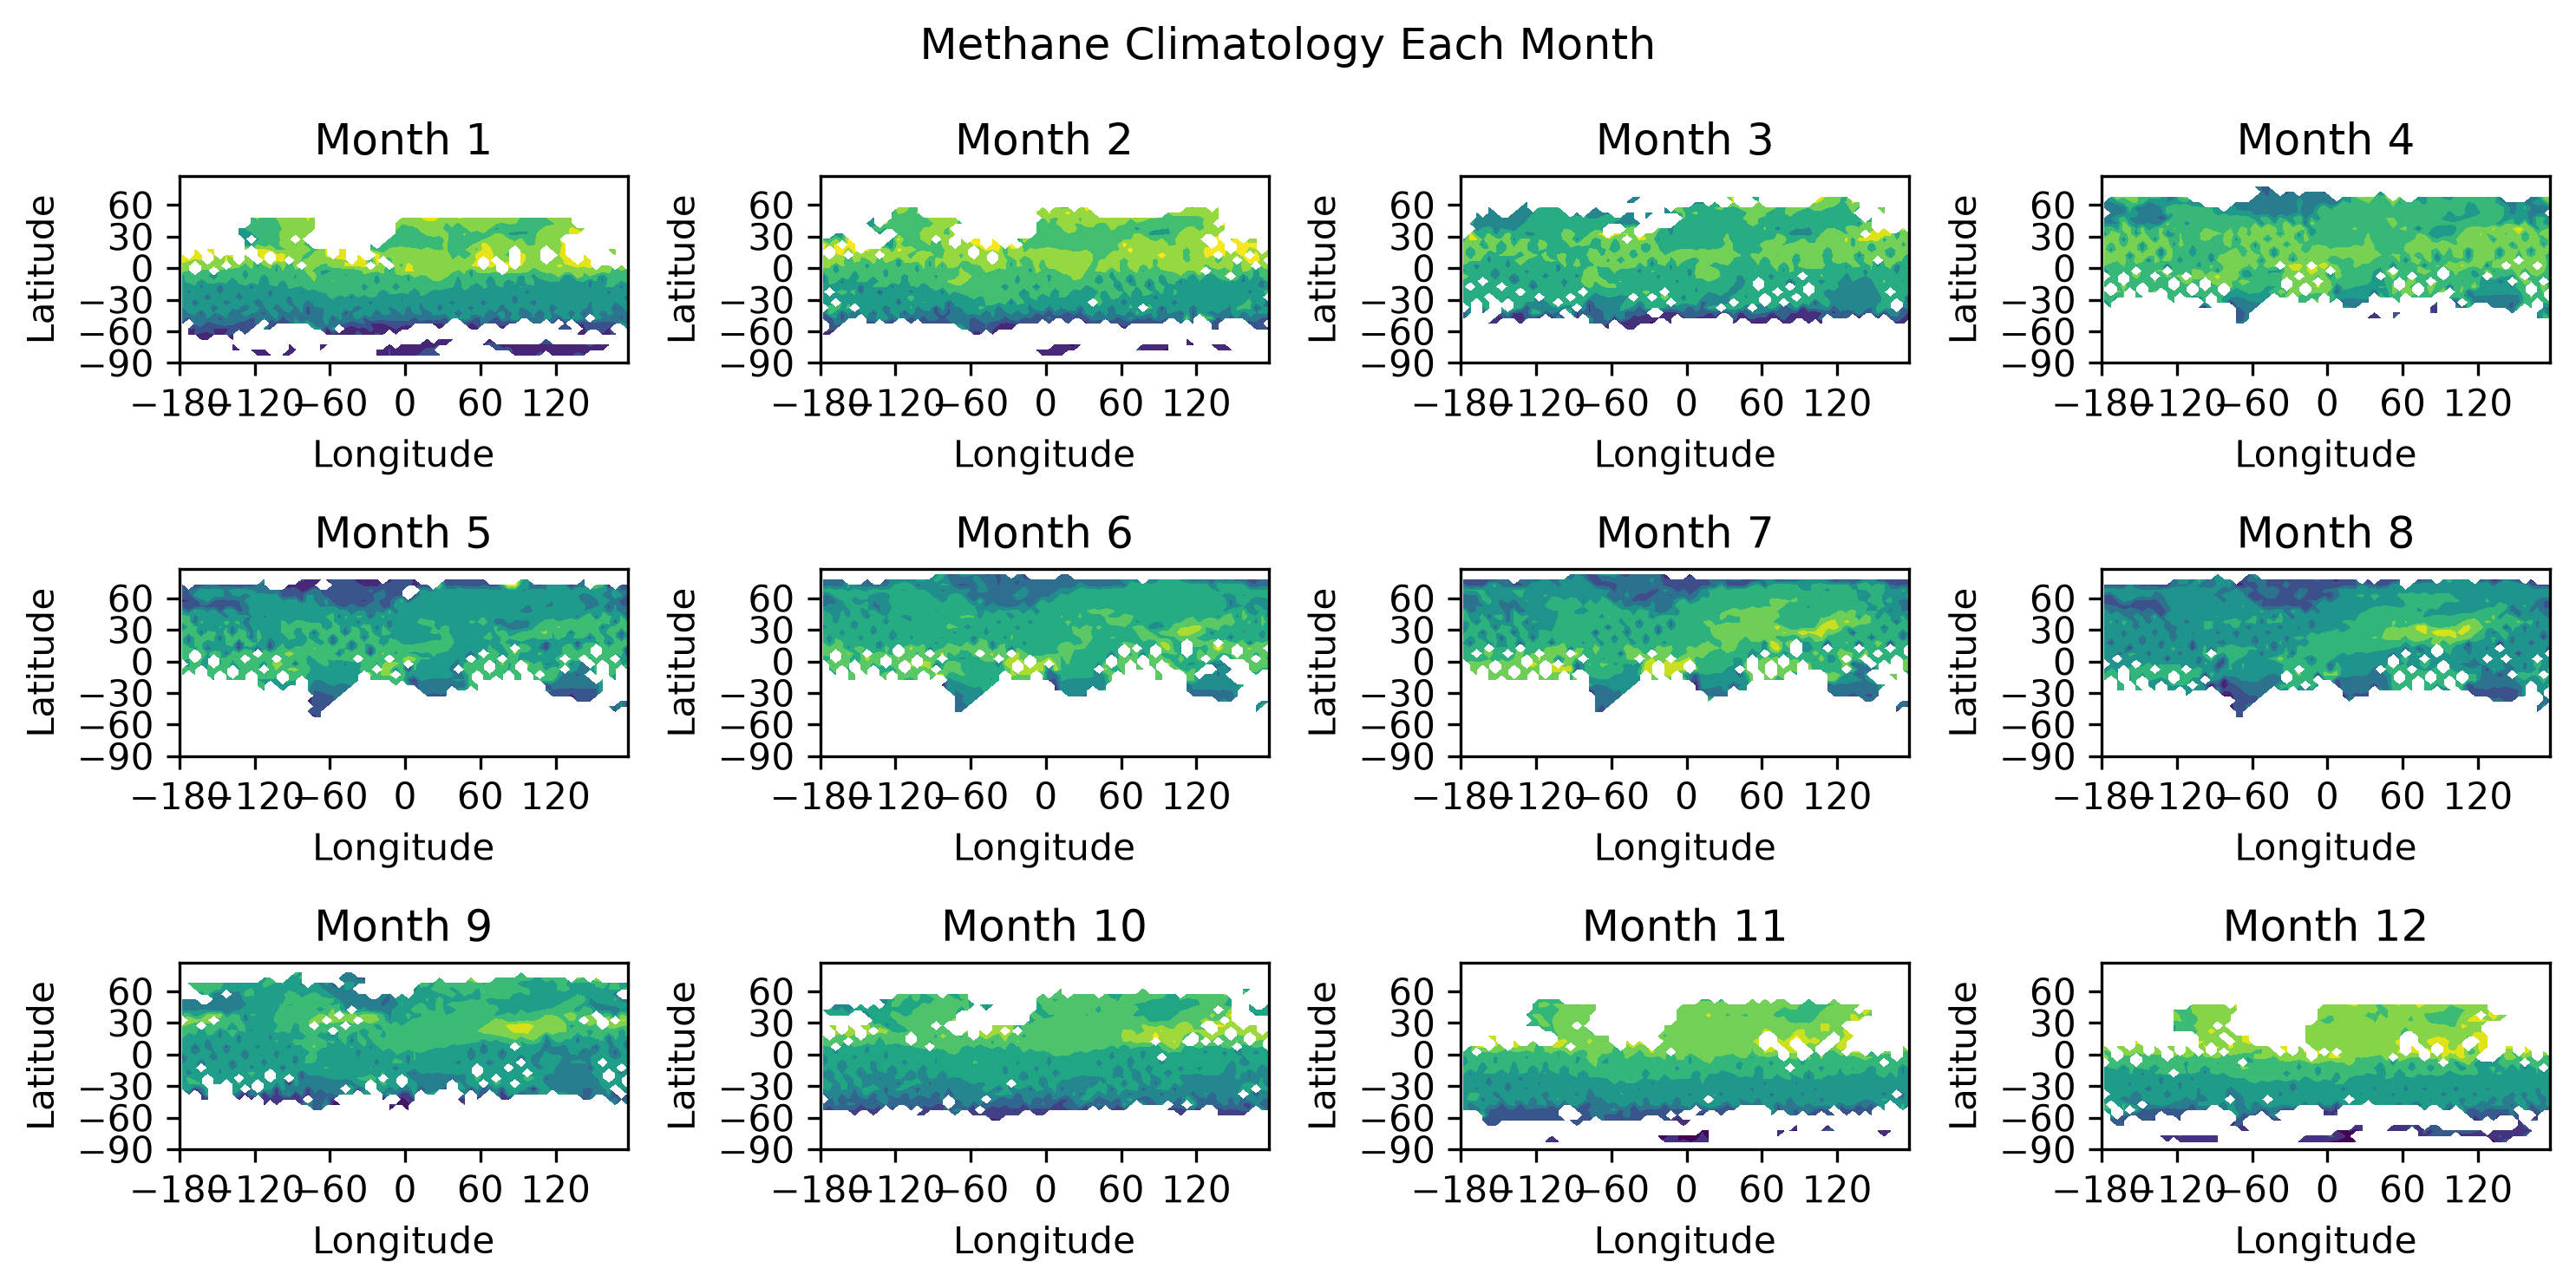

In [80]:
# 1.1

# 获取 XCH4 每月的 climatology（多年平均）数据
ds1_c = ds1.xch4.groupby('time.month').mean(dim='time')

# 画图
fig, axes = plt.subplots(3, 4, figsize=(10,5), dpi=300)

for i, ax in enumerate(axes.ravel()):   
    ds1_c[i].plot.contourf(ax=ax, x='lon', y='lat', add_colorbar=False)
    ax.set_title(f'Month {i+1}')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_xticks(ticks=np.arange(-180,180,60))
    ax.set_yticks(ticks=np.arange(-90,90,30))
    
plt.suptitle('Methane Climatology Each Month')
plt.tight_layout()
plt.show()

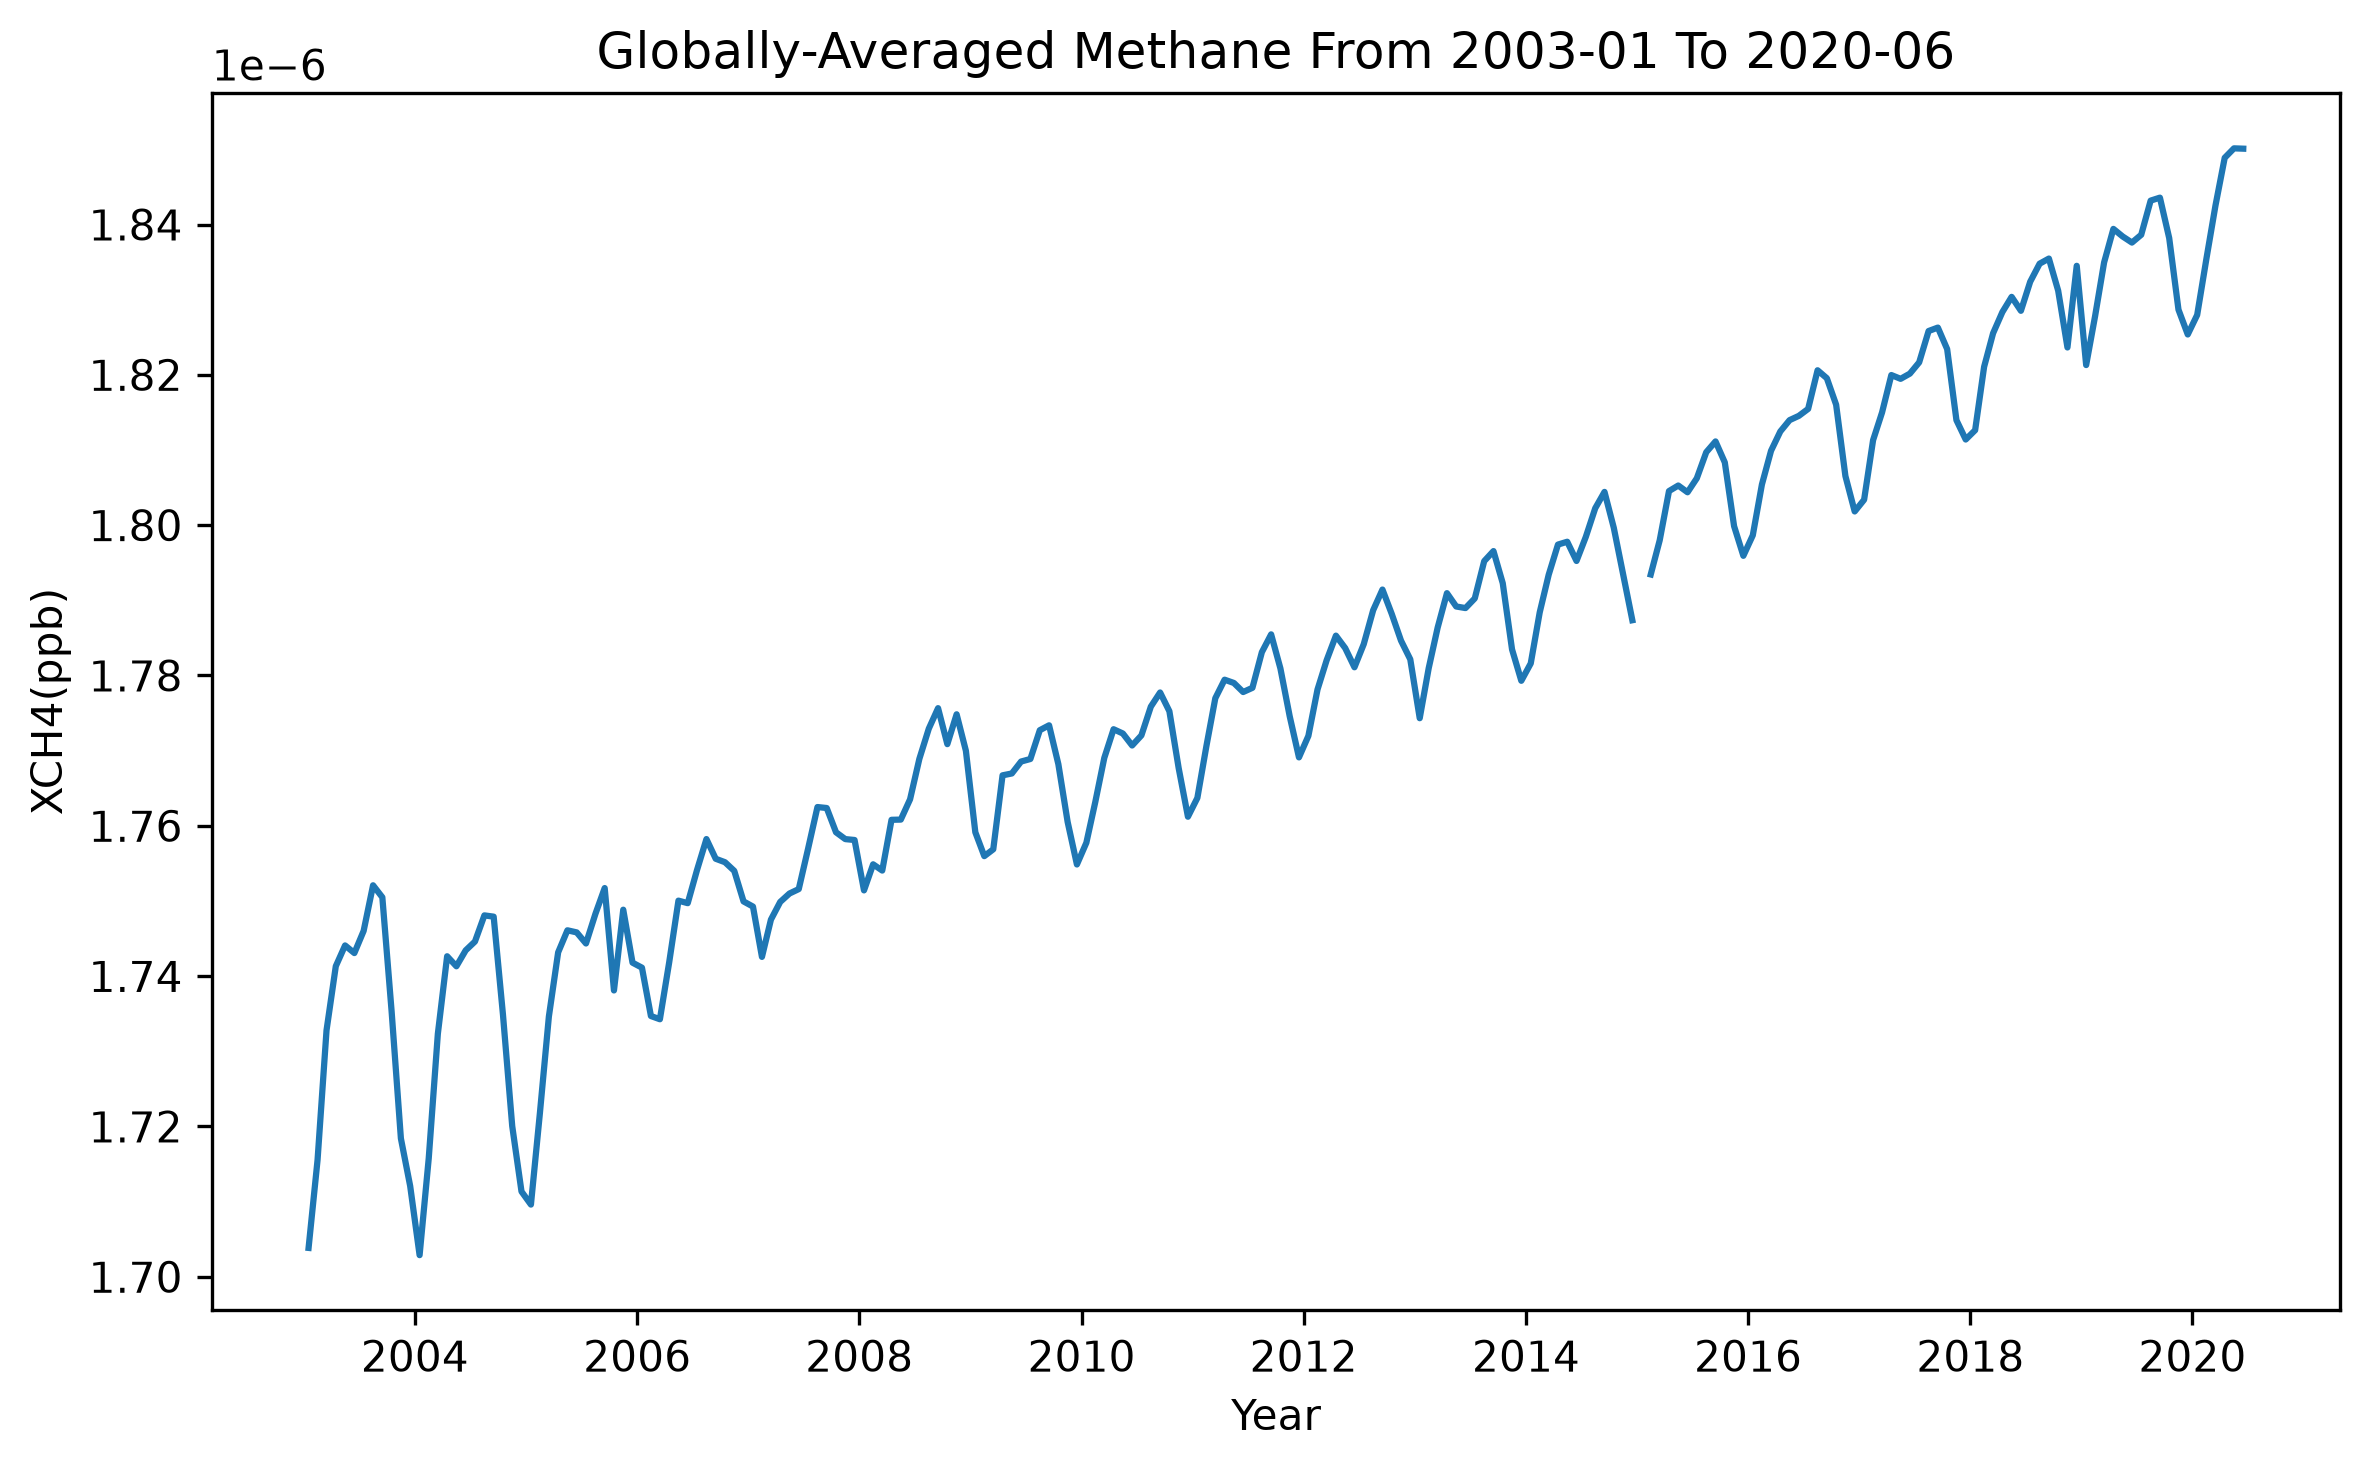

In [82]:
# 1.2

# 获取 XCH42003-01 到 2020-06 的全球平均数据
ds1_ga = ds1.xch4.mean(dim=['lon','lat']).sel(time=slice('2003-01','2020-06'))

# 画图
plt.figure(figsize=(8,5), dpi=300) 
plt.plot(ds1['time'], ds1_ga)
plt.title('Globally-Averaged Methane From 2003-01 To 2020-06')
plt.xlabel('Year')
plt.ylabel('XCH4(ppb)')
plt.tight_layout()
plt.show()

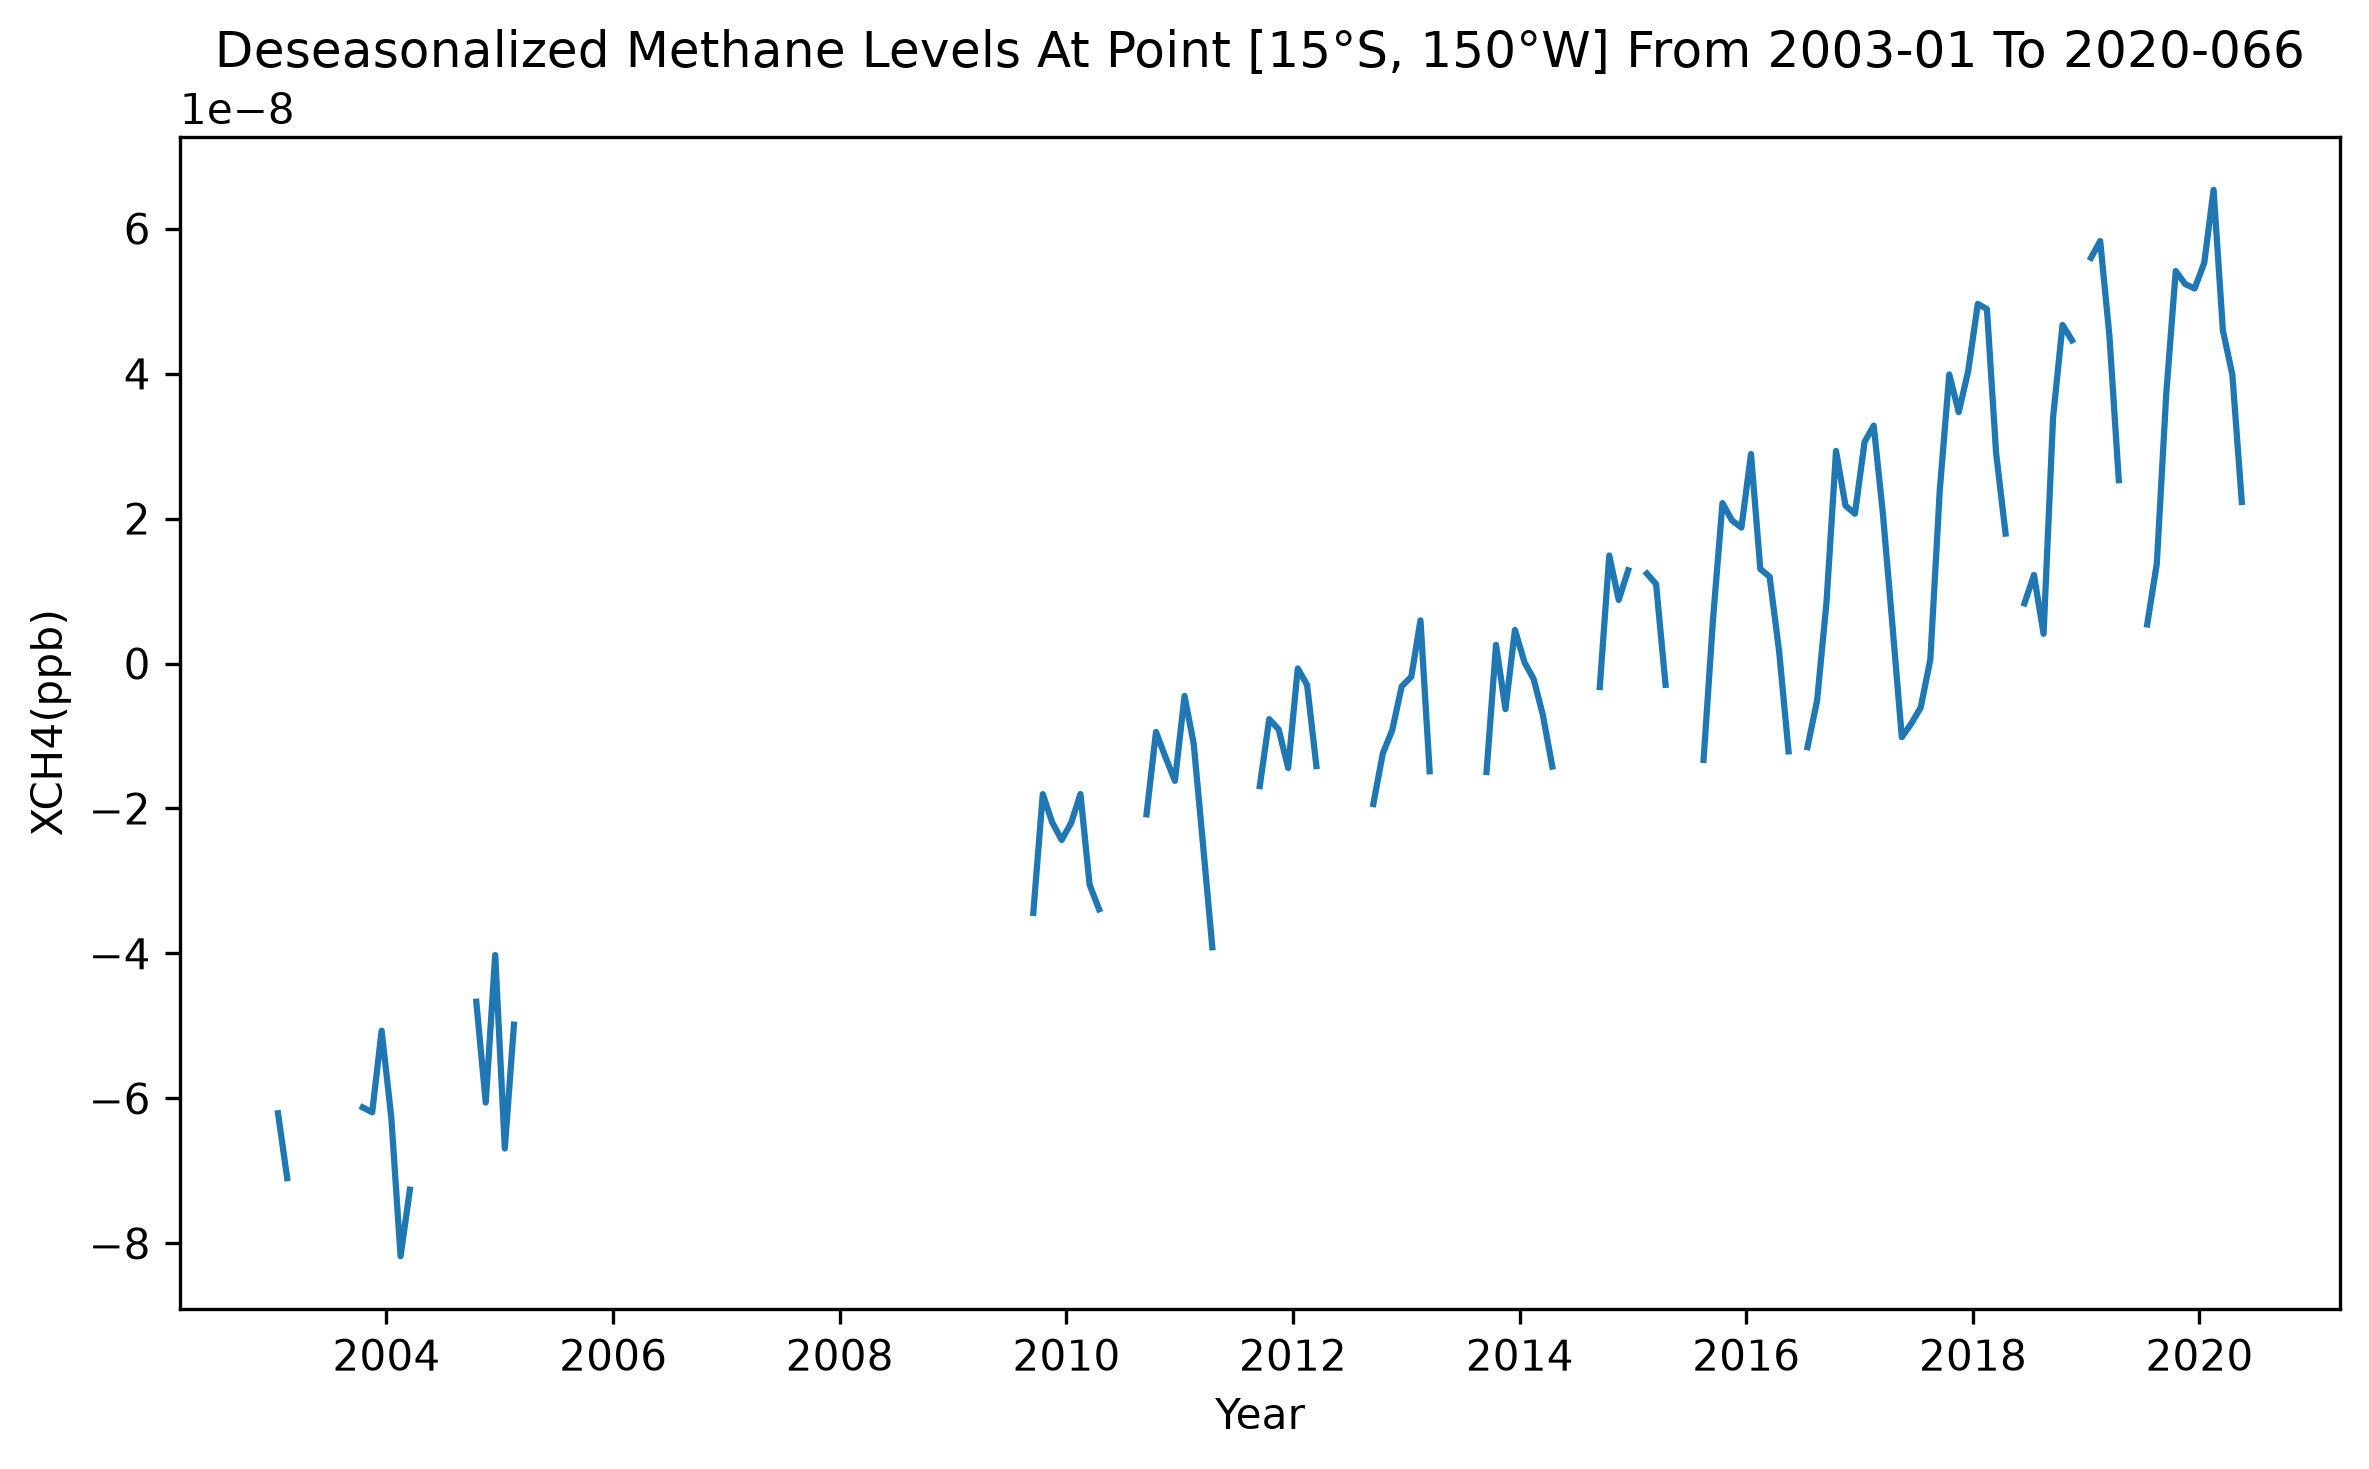

In [86]:
# 1.3

# 先获取指定点和时间段的数据，因为 [15°S, 150°W] 恰好位于 4 个网格节点的中心，所以这里使用 4 个节点的平均值代替
ds1_pa = ds1.xch4.sel(lon=[-152.5, -147.5],lat=[-17.5,-12.5],time=slice('2003-01','2020-06')).mean(dim=['lon','lat'])

# 对 ds1_pa 去季节化，剔除周期波动，也就是计算距平
ds1_pa_de = ds1_pa.groupby('time.month') - ds1_pa.groupby('time.month').mean(dim='time')

# 画图
plt.figure(figsize=(8,5), dpi=300) 
plt.plot(ds1['time'], ds1_pa_de)
plt.title('Deseasonalized Methane Levels At Point [15°S, 150°W] From 2003-01 To 2020-066')
plt.xlabel('Year')
plt.ylabel('XCH4(ppb)')

plt.tight_layout()
plt.show()

In [89]:
# 2

# 读取数据
ds2 = xr.open_dataset('NOAA_NCDC_ERSST_v3b_SST.nc', engine='netcdf4')

In [69]:
# 2.1

# 先获取 Nino 3.4 区域经纬度的平均值
ds2_nino34 = ds2.sst.sel(lon=slice(190,240),lat=slice(-5,5)).mean(dim=['lon','lat'])

# 创建一个 copy 确保新的变量 coords 中也包括 time
ds2_tmra = ds2_nino34.copy()

# 把新变量全部值替换为 nan（空值），方便后续填充
ds2_tmra[:] = np.nan

# 根据 ONI 的定义，需要计算包括每个月自身与其前一个月、后一个月三者的滑动平均
for i in np.arange(0, len(ds2_nino34)):
    if (i != 0) and (i != len(ds2_nino34)-1):
        ds2_tmra[i] = (ds2_nino34[i-1]+ds2_nino34[i]+ds2_nino34[i+1])/3

# 计算距平
ds2['tmra'] = ds2_tmra
ds2['oni'] = ds2.tmra.groupby('time.month') - ds2.tmra.groupby('time.month').mean(dim='time')
ds2.oni.values

array([            nan, -3.52087021e-01, -3.07880402e-01, -2.10906982e-01,
       -2.40751266e-01, -2.25753784e-01, -1.61668777e-01, -9.31758881e-02,
       -1.72473907e-01, -2.97658920e-01, -3.16484451e-01, -2.66458511e-01,
       -1.87932968e-01, -1.88713074e-01, -1.86595917e-01, -1.24530792e-01,
        3.53889465e-02,  7.36541748e-02, -8.32176208e-02, -4.22449112e-01,
       -6.63131714e-01, -6.88997269e-01, -5.68662643e-01, -4.65568542e-01,
       -4.49125290e-01, -4.45587158e-01, -4.52966690e-01, -4.89166260e-01,
       -4.86116409e-01, -4.22714233e-01, -3.40274811e-01, -4.22365189e-01,
       -5.52162170e-01, -7.18994141e-01, -7.83102036e-01, -8.07634354e-01,
       -6.51090622e-01, -3.29607010e-01, -3.80039215e-02,  5.07850647e-02,
        5.32169342e-02,  2.24630356e-01,  5.19939423e-01,  7.31958389e-01,
        7.80830383e-01,  8.18588257e-01,  9.42890167e-01,  9.35888290e-01,
        8.10497284e-01,  4.14802551e-01, -8.05034637e-02, -5.42297363e-01,
       -8.14098358e-01, -

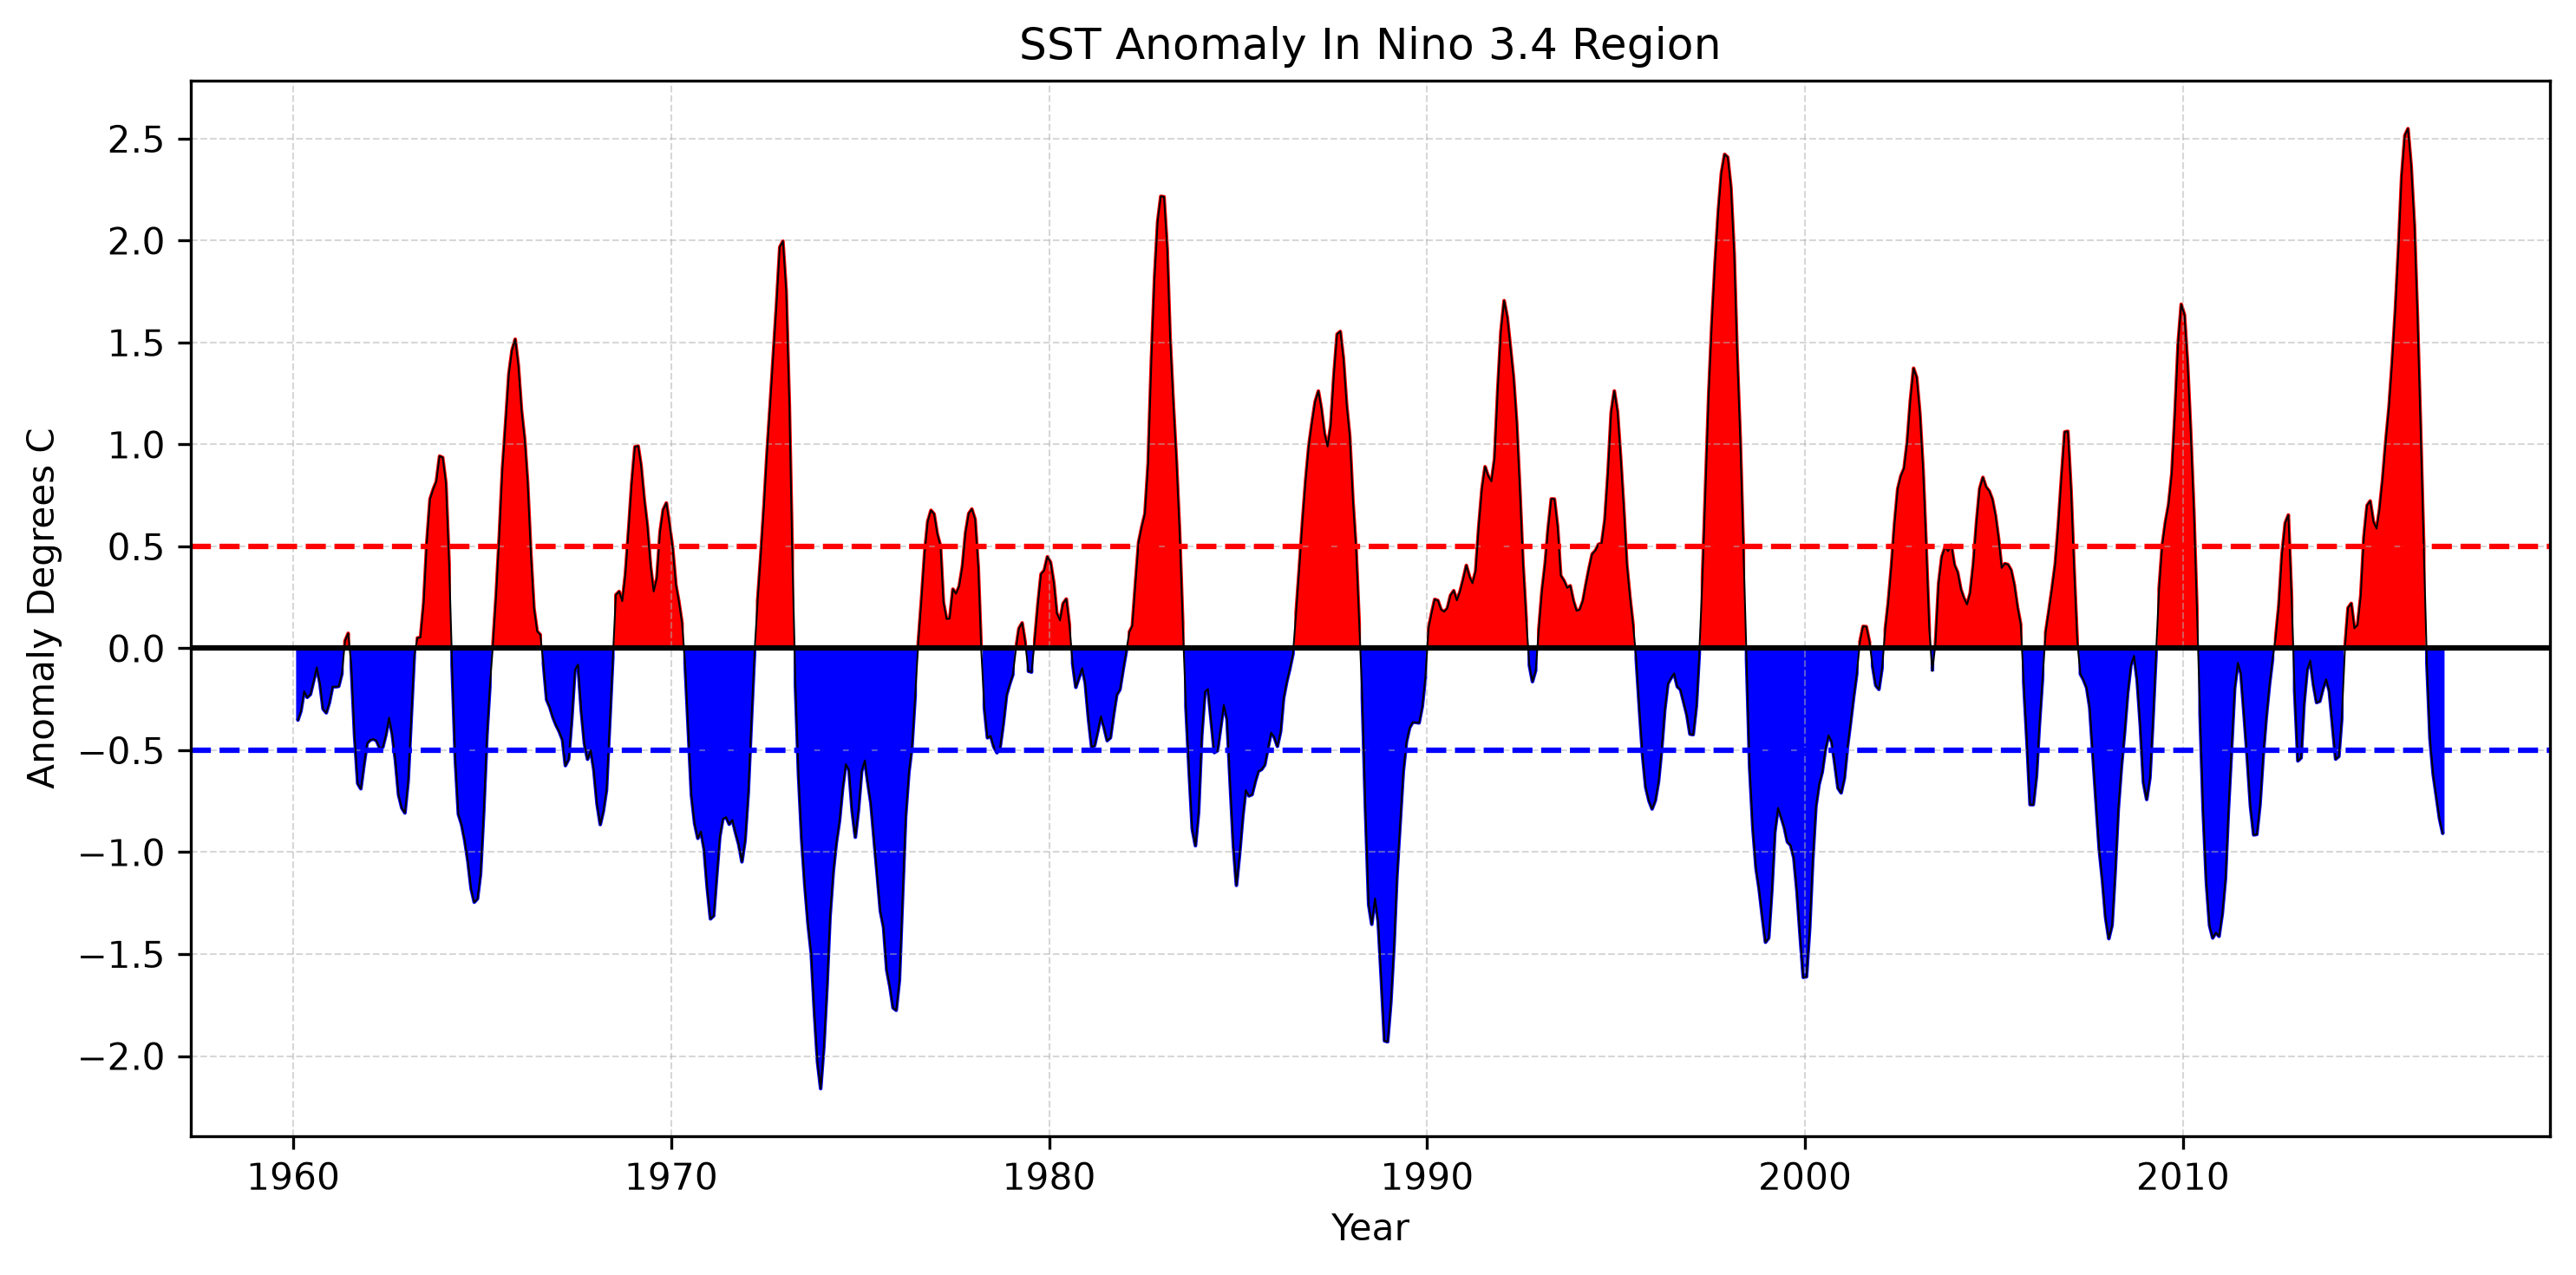

In [70]:
# 2.2

# 画图
fig, ax = plt.subplots(figsize=(10,5), dpi=300) 
ax.plot(ds2['date'], ds2.oni, 'k', linewidth=0.5)

# 仿照示例，把曲线大于 0 的部分与横轴围成的面积填充成红色，把曲线小于 0 的部分与横轴围成的面积填充成蓝色
ax.fill_between(ds2['date'], ds2.oni, where=(ds2.oni>0), color='red')
ax.fill_between(ds2['date'], ds2.oni, where=(ds2.oni<0), color='blue')

# 画出 y=0，y=0.5，和 y=-0.5 三条水平线
ax.axhline(0, color='black')
ax.axhline(0.5, color='red', linestyle='--')
ax.axhline(-0.5, color='blue', linestyle='--')

plt.title('SST Anomaly In Nino 3.4 Region')
plt.xlabel('Year')
plt.ylabel('Anomaly Degrees C')
plt.yticks(ticks=np.arange(-2,3,0.5))
plt.grid(linestyle='--', linewidth=0.5, alpha=0.5)

plt.tight_layout()
plt.show()

In [71]:
# 3

# 因为 GES DISC 的数据大多是一个月对应一个.nc文件，即一个.nc文件中 time 只有 1 个值，而每个.nc文件又有几十 MB，
# 所以参照官方给出的 tutorial 对数据进行剪切，代码来自于：
# https://github.com/nasa/gesdisc-tutorials/blob/main/notebooks/How_to_Subset_and_Download_L234_Data_Using_Python.ipynb
# 需要在 Earthdata 创建一个账户，我的账户：ashui0328，密码：Earthdata0071.

# 调用对应的 library
import os
from datetime import datetime
import earthaccess
import xarray as xr
from harmony import BBox, Client, Collection, Request

# 数据集的参数
SHORT_NAME = 'M2TMNXADG'
VERSION = '5.12.4'
OUT_DIR = 'M2TMNXADG_subset'

# 中国区域
WEST, SOUTH, EAST, NORTH = 73, 3, 136, 54

# 时间范围
START = datetime(2010, 1, 1)
STOP = datetime(2020, 12, 31)

# 需要截取的变量
VARIABLES = ['DUAERIDX', 'DUDP001', 'DUDP002', 'DUDP003', 'DUDP004', 'DUDP005']

# 登录 Earthdata
earthaccess.login(strategy='interactive', persist=True)

# 查找 collection
collections = earthaccess.search_datasets(
    short_name=SHORT_NAME,
    version=VERSION,
)

concept_id = collections[0].concept_id

# 构造 Harmony 请求
request = Request(
    collection=Collection(id=concept_id),
    spatial=BBox(WEST, SOUTH, EAST, NORTH),
    temporal={
        'start': START,
        'stop': STOP,
    },
    variables=VARIABLES,
)

# 提交并等待
client = Client()

job_id = client.submit(request)

# 下载
os.makedirs(OUT_DIR, exist_ok=True)

downloaded = client.download_all(job_id, directory=OUT_DIR)

files = []

if downloaded is not None:
    for item in downloaded:
        path = item.result() if hasattr(item, 'result') else item
        if path is not None:
            files.append(os.fspath(path))

files = sorted(files)

# 合并
ds = xr.open_mfdataset(
    files,
    combine='by_coords',
    decode_times=True,
)

M2TMNXADG_subset\456803343_M2TMNXADG.5.12.4_MERRA2_300.tavgM_2d_adg_Nx.201001_subsetted.nc4
M2TMNXADG_subset\456803345_M2TMNXADG.5.12.4_MERRA2_300.tavgM_2d_adg_Nx.201003_subsetted.nc4
M2TMNXADG_subset\456803344_M2TMNXADG.5.12.4_MERRA2_300.tavgM_2d_adg_Nx.201002_subsetted.nc4
M2TMNXADG_subset\456803346_M2TMNXADG.5.12.4_MERRA2_300.tavgM_2d_adg_Nx.201004_subsetted.nc4
M2TMNXADG_subset\456803348_M2TMNXADG.5.12.4_MERRA2_300.tavgM_2d_adg_Nx.201006_subsetted.nc4
M2TMNXADG_subset\456803347_M2TMNXADG.5.12.4_MERRA2_300.tavgM_2d_adg_Nx.201005_subsetted.nc4
M2TMNXADG_subset\456803349_M2TMNXADG.5.12.4_MERRA2_300.tavgM_2d_adg_Nx.201007_subsetted.nc4
M2TMNXADG_subset\456803350_M2TMNXADG.5.12.4_MERRA2_300.tavgM_2d_adg_Nx.201008_subsetted.nc4
M2TMNXADG_subset\456803351_M2TMNXADG.5.12.4_MERRA2_300.tavgM_2d_adg_Nx.201009_subsetted.nc4
M2TMNXADG_subset\456803352_M2TMNXADG.5.12.4_MERRA2_300.tavgM_2d_adg_Nx.201010_subsetted.nc4
M2TMNXADG_subset\456803353_M2TMNXADG.5.12.4_MERRA2_300.tavgM_2d_adg_Nx.201011_su

In [72]:
ds.data_vars
# DUDP001-DUDP005：5 个粒径的沙尘干沉降
# DUAERIDX：沙尘 TOMS UV 气溶胶指数

Data variables:
    DUDP001   (time, lat, lon) float32 6MB dask.array<chunksize=(1, 103, 102), meta=np.ndarray>
    DUDP005   (time, lat, lon) float32 6MB dask.array<chunksize=(1, 103, 102), meta=np.ndarray>
    DUAERIDX  (time, lat, lon) float32 6MB dask.array<chunksize=(1, 103, 102), meta=np.ndarray>
    DUDP002   (time, lat, lon) float32 6MB dask.array<chunksize=(1, 103, 102), meta=np.ndarray>
    DUDP003   (time, lat, lon) float32 6MB dask.array<chunksize=(1, 103, 102), meta=np.ndarray>
    DUDP004   (time, lat, lon) float32 6MB dask.array<chunksize=(1, 103, 102), meta=np.ndarray>

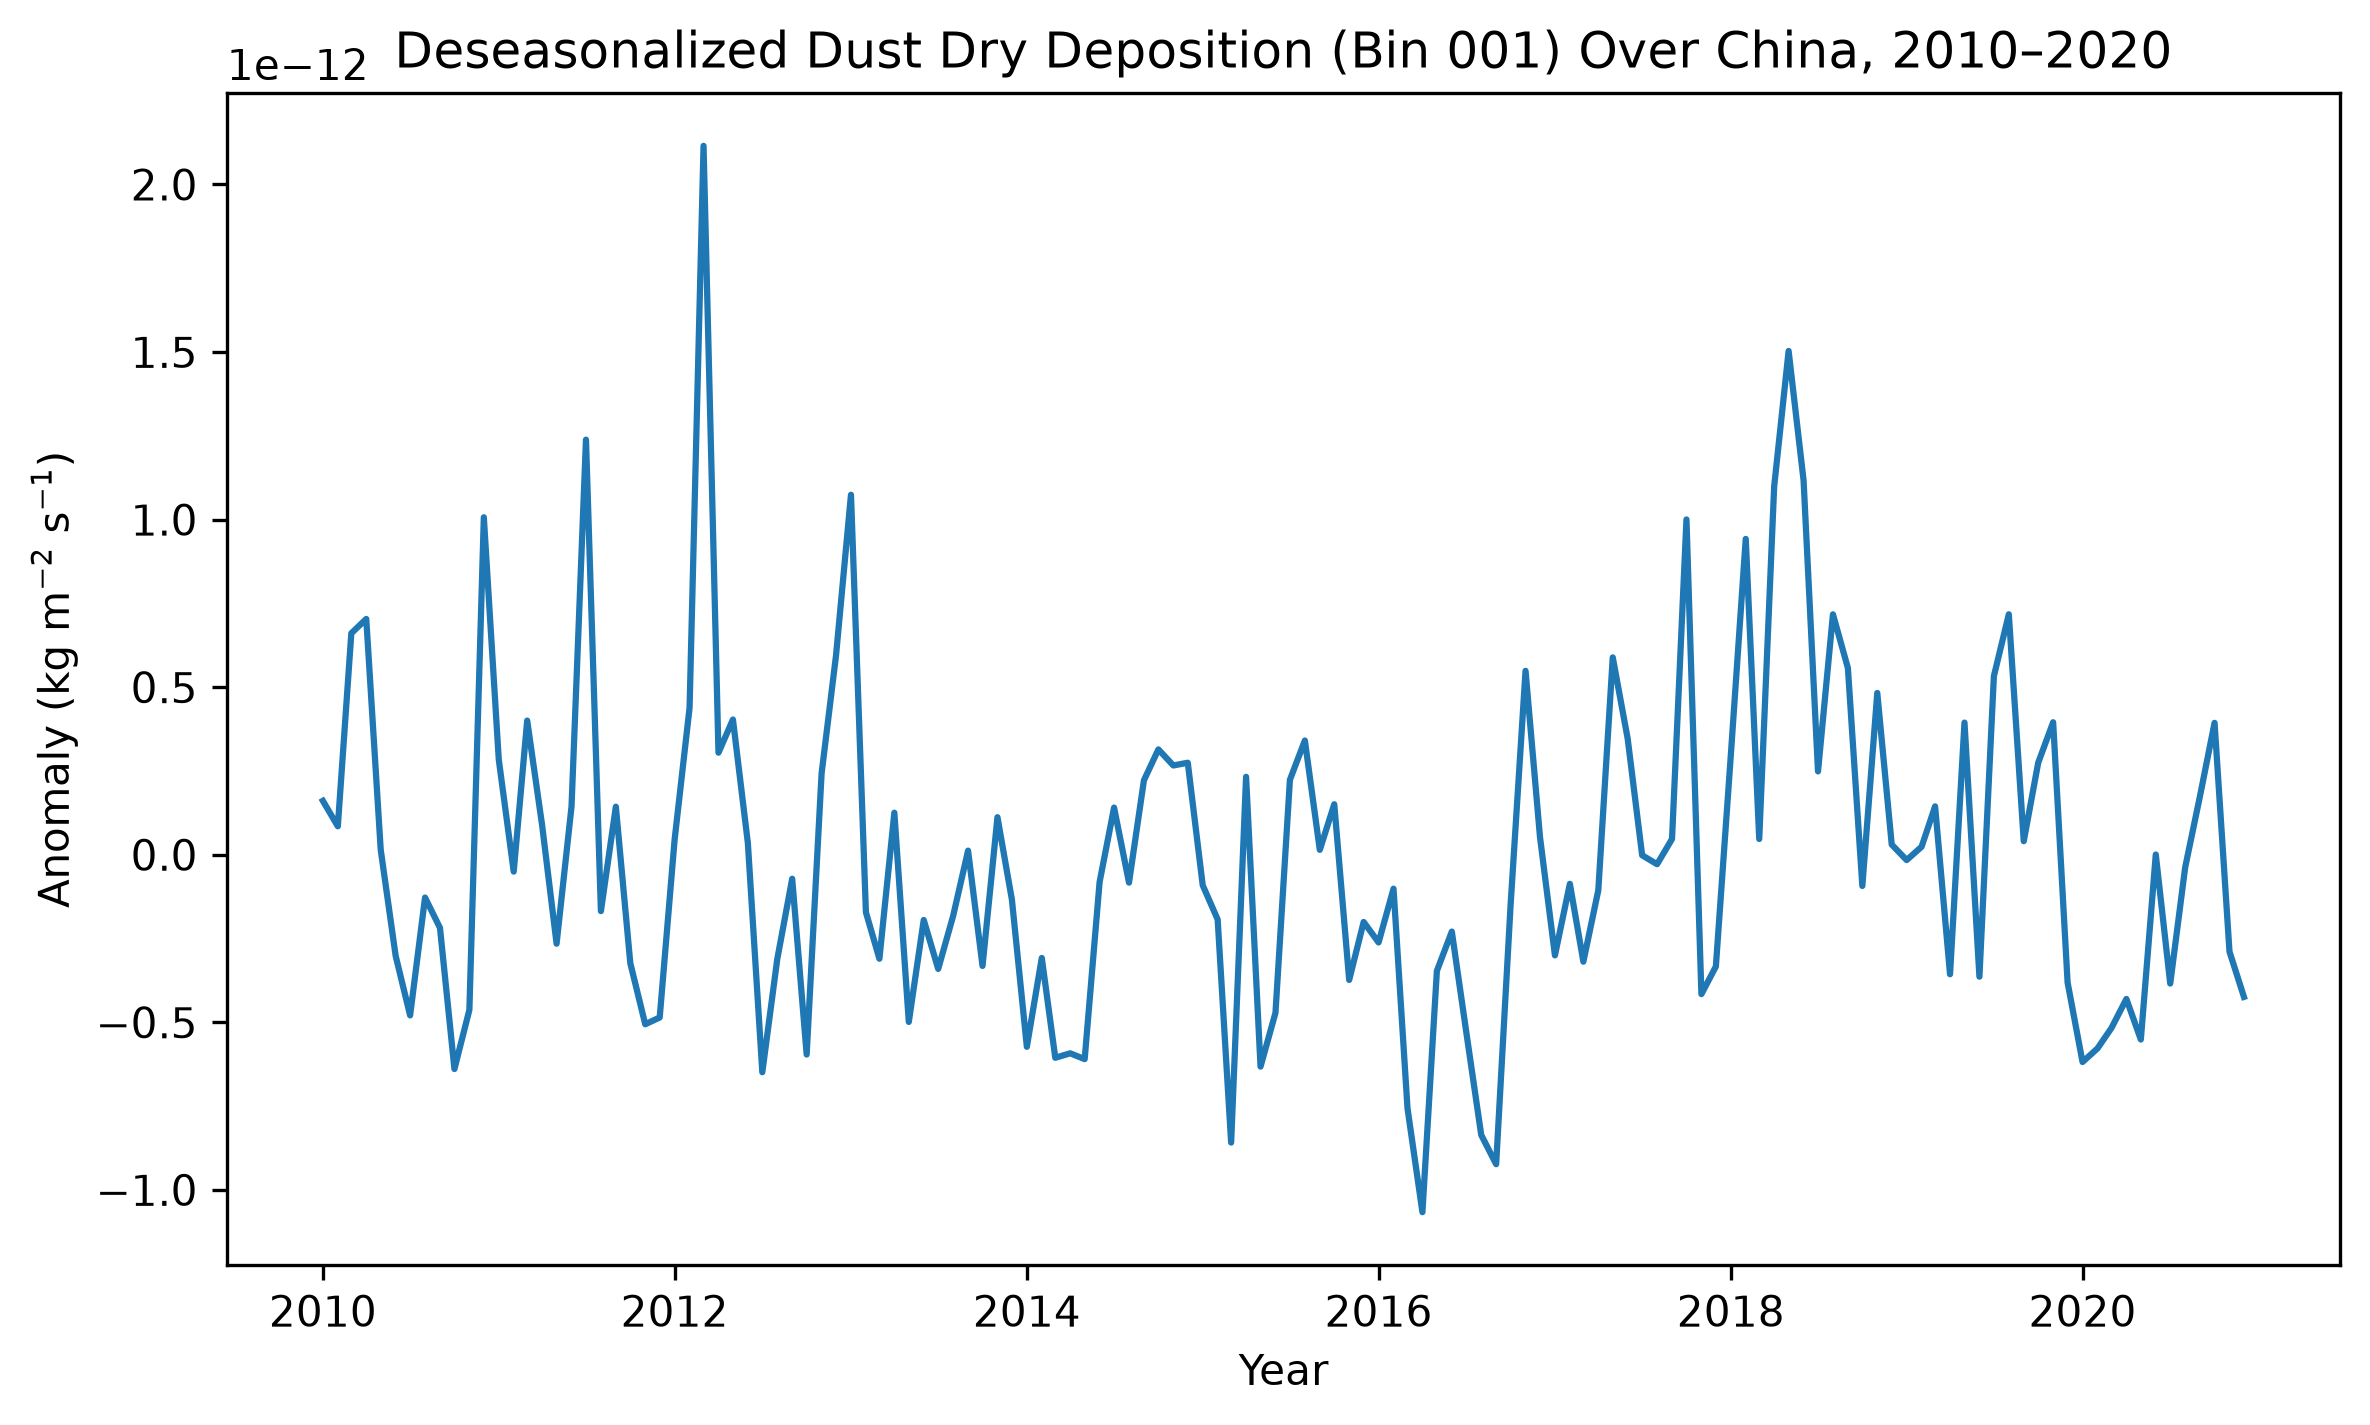

In [90]:
# 3.1

# 计算去季节性的沙尘排放的第 1 个粒径档的数据
anom = ds.DUDP001.mean(dim=['lon','lat']).groupby('time.month') - ds.DUDP001.mean(dim=['lon','lat']).groupby('time.month').mean(dim='time')
ds['date'] = pd.to_datetime(ds['time'])

# 画图
plt.figure(figsize=(8,5), dpi=300) 
plt.plot(ds['date'], anom)
plt.title('Deseasonalized Dust Dry Deposition (Bin 001) Over China, 2010–2020')
plt.xlabel('Year')
plt.ylabel(r'Anomaly (kg m$^{-2}$ s$^{-1}$)')

plt.tight_layout()
plt.show()

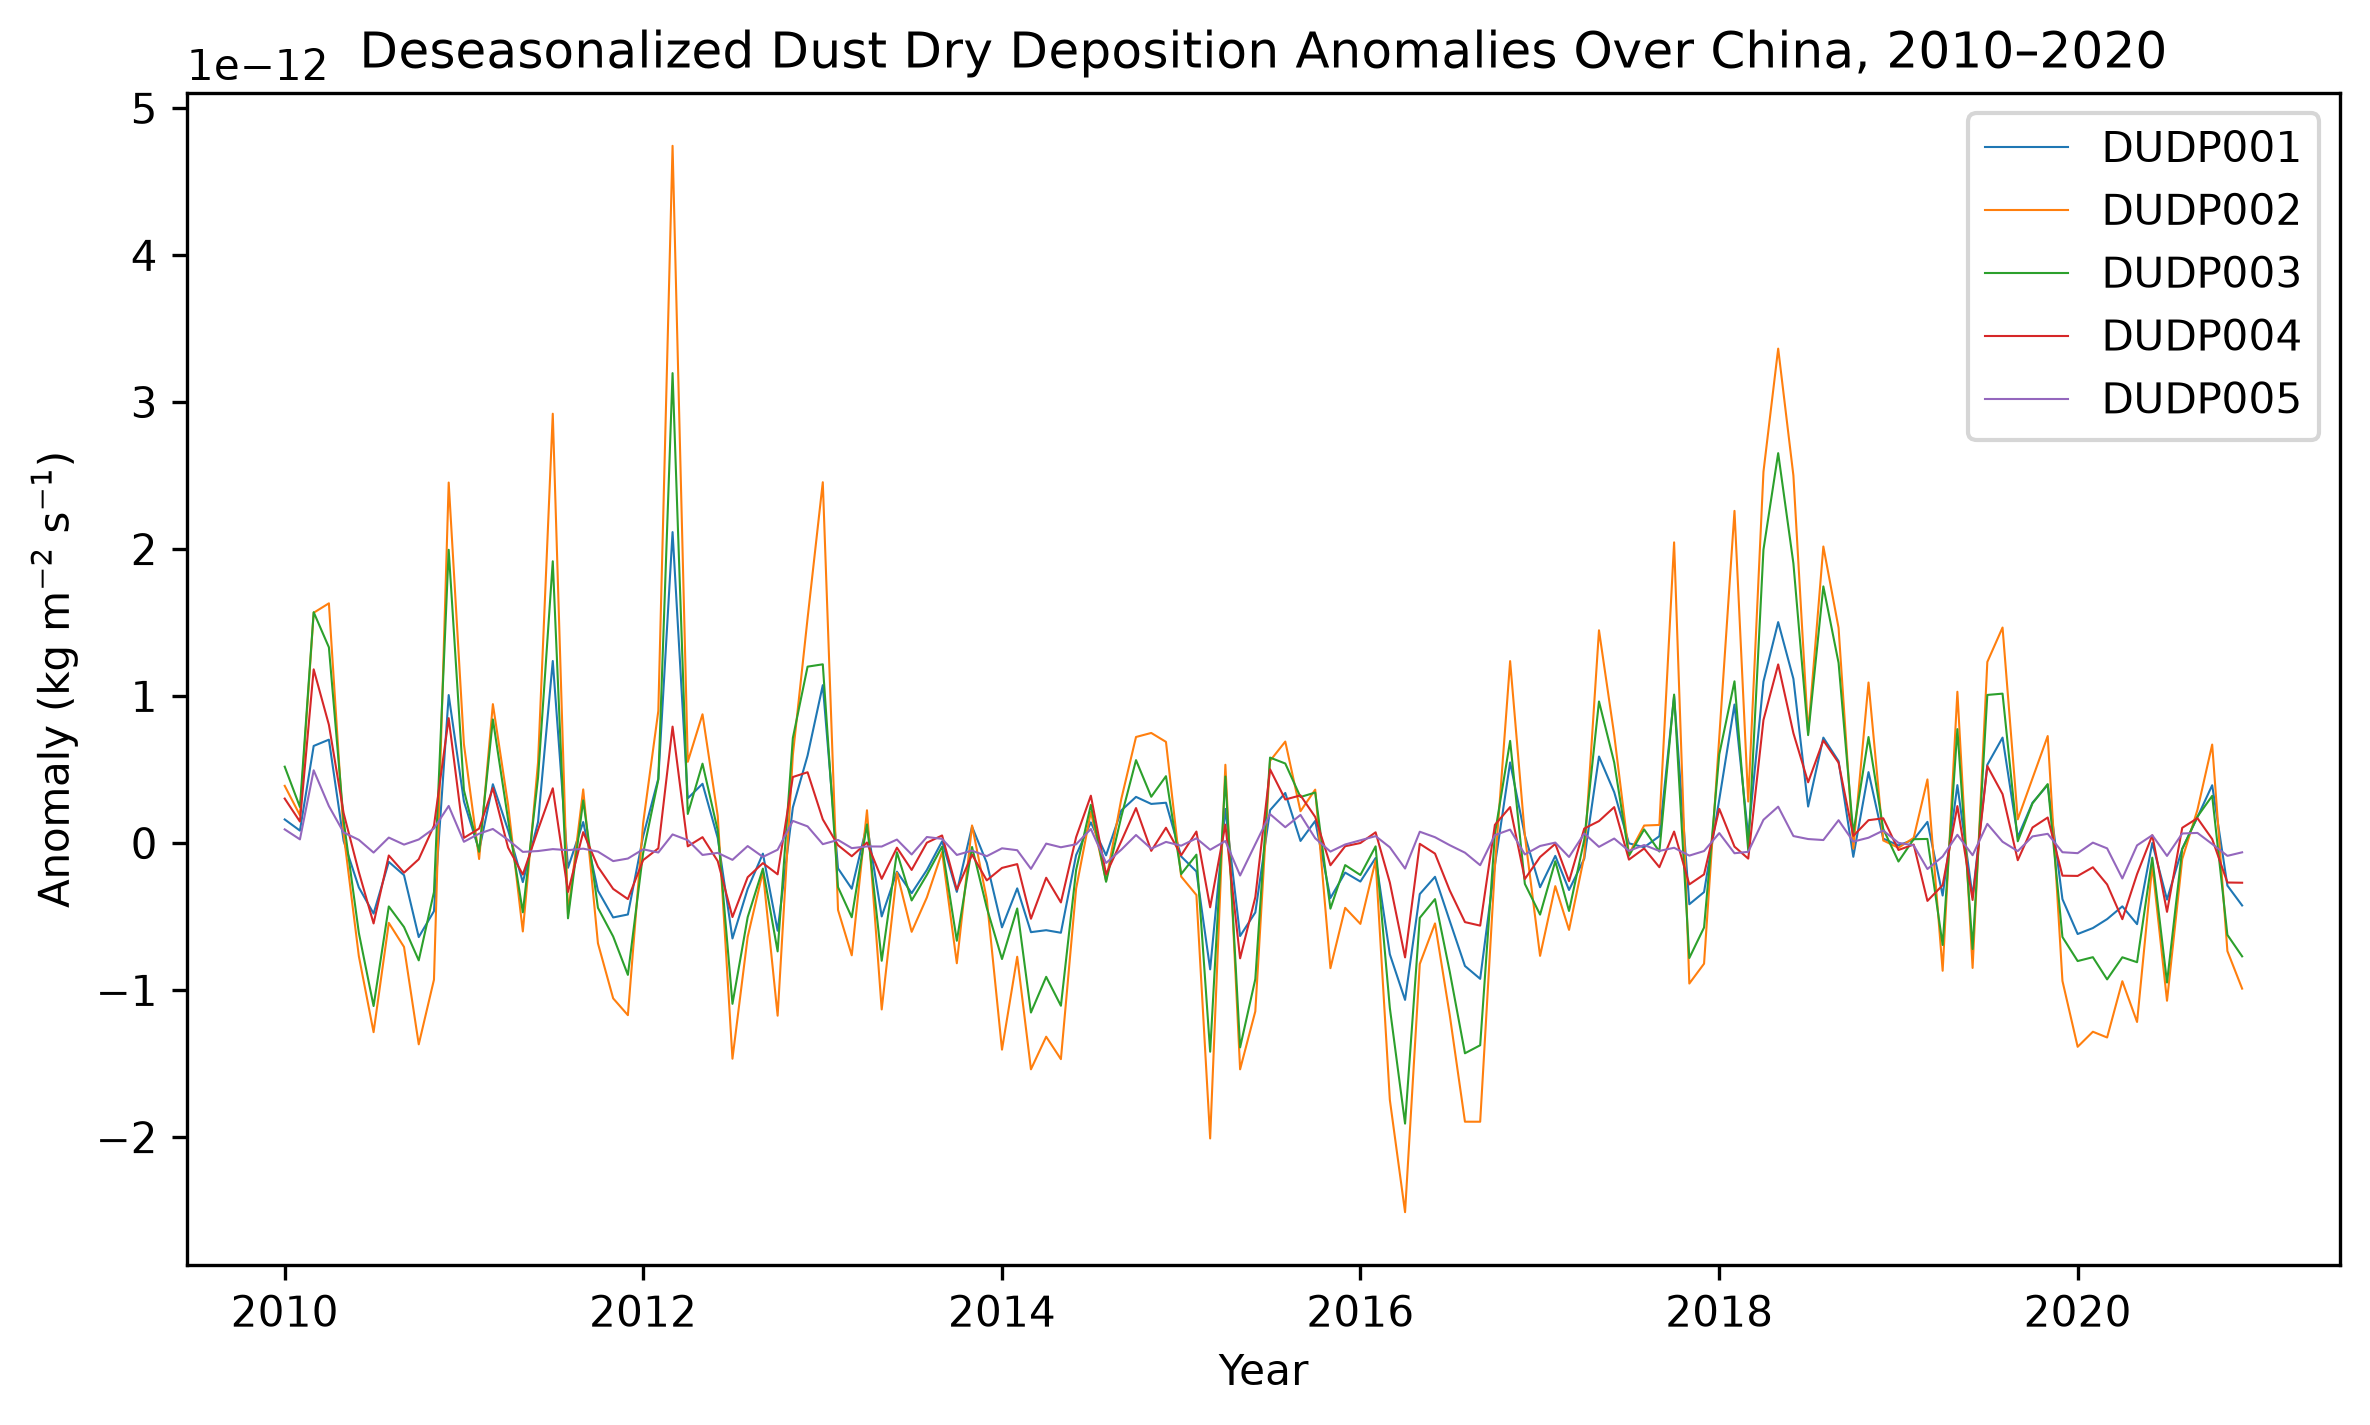

In [74]:
# 3.2

# 图 1：5个粒径的去季节性时间序列图
# 编号
bins = [f'DUDP00{i}' for i in np.arange(1, 6)]
# 区域平均
da = ds.mean(dim=['lon','lat'])
# 距平
anom = da.groupby('time.month') - da.groupby('time.month').mean(dim='time')
# 画图
fig, ax = plt.subplots(figsize=(8, 5), dpi=300)
for i in np.arange(5):
    ax.plot(ds['date'], anom[bins[i]], linewidth=0.5, label=bins[i])

ax.set_title('Deseasonalized Dust Dry Deposition Anomalies Over China, 2010–2020')
ax.set_xlabel('Year')
ax.set_ylabel(r'Anomaly (kg m$^{-2}$ s$^{-1}$)')
ax.legend()
plt.tight_layout()
plt.show()

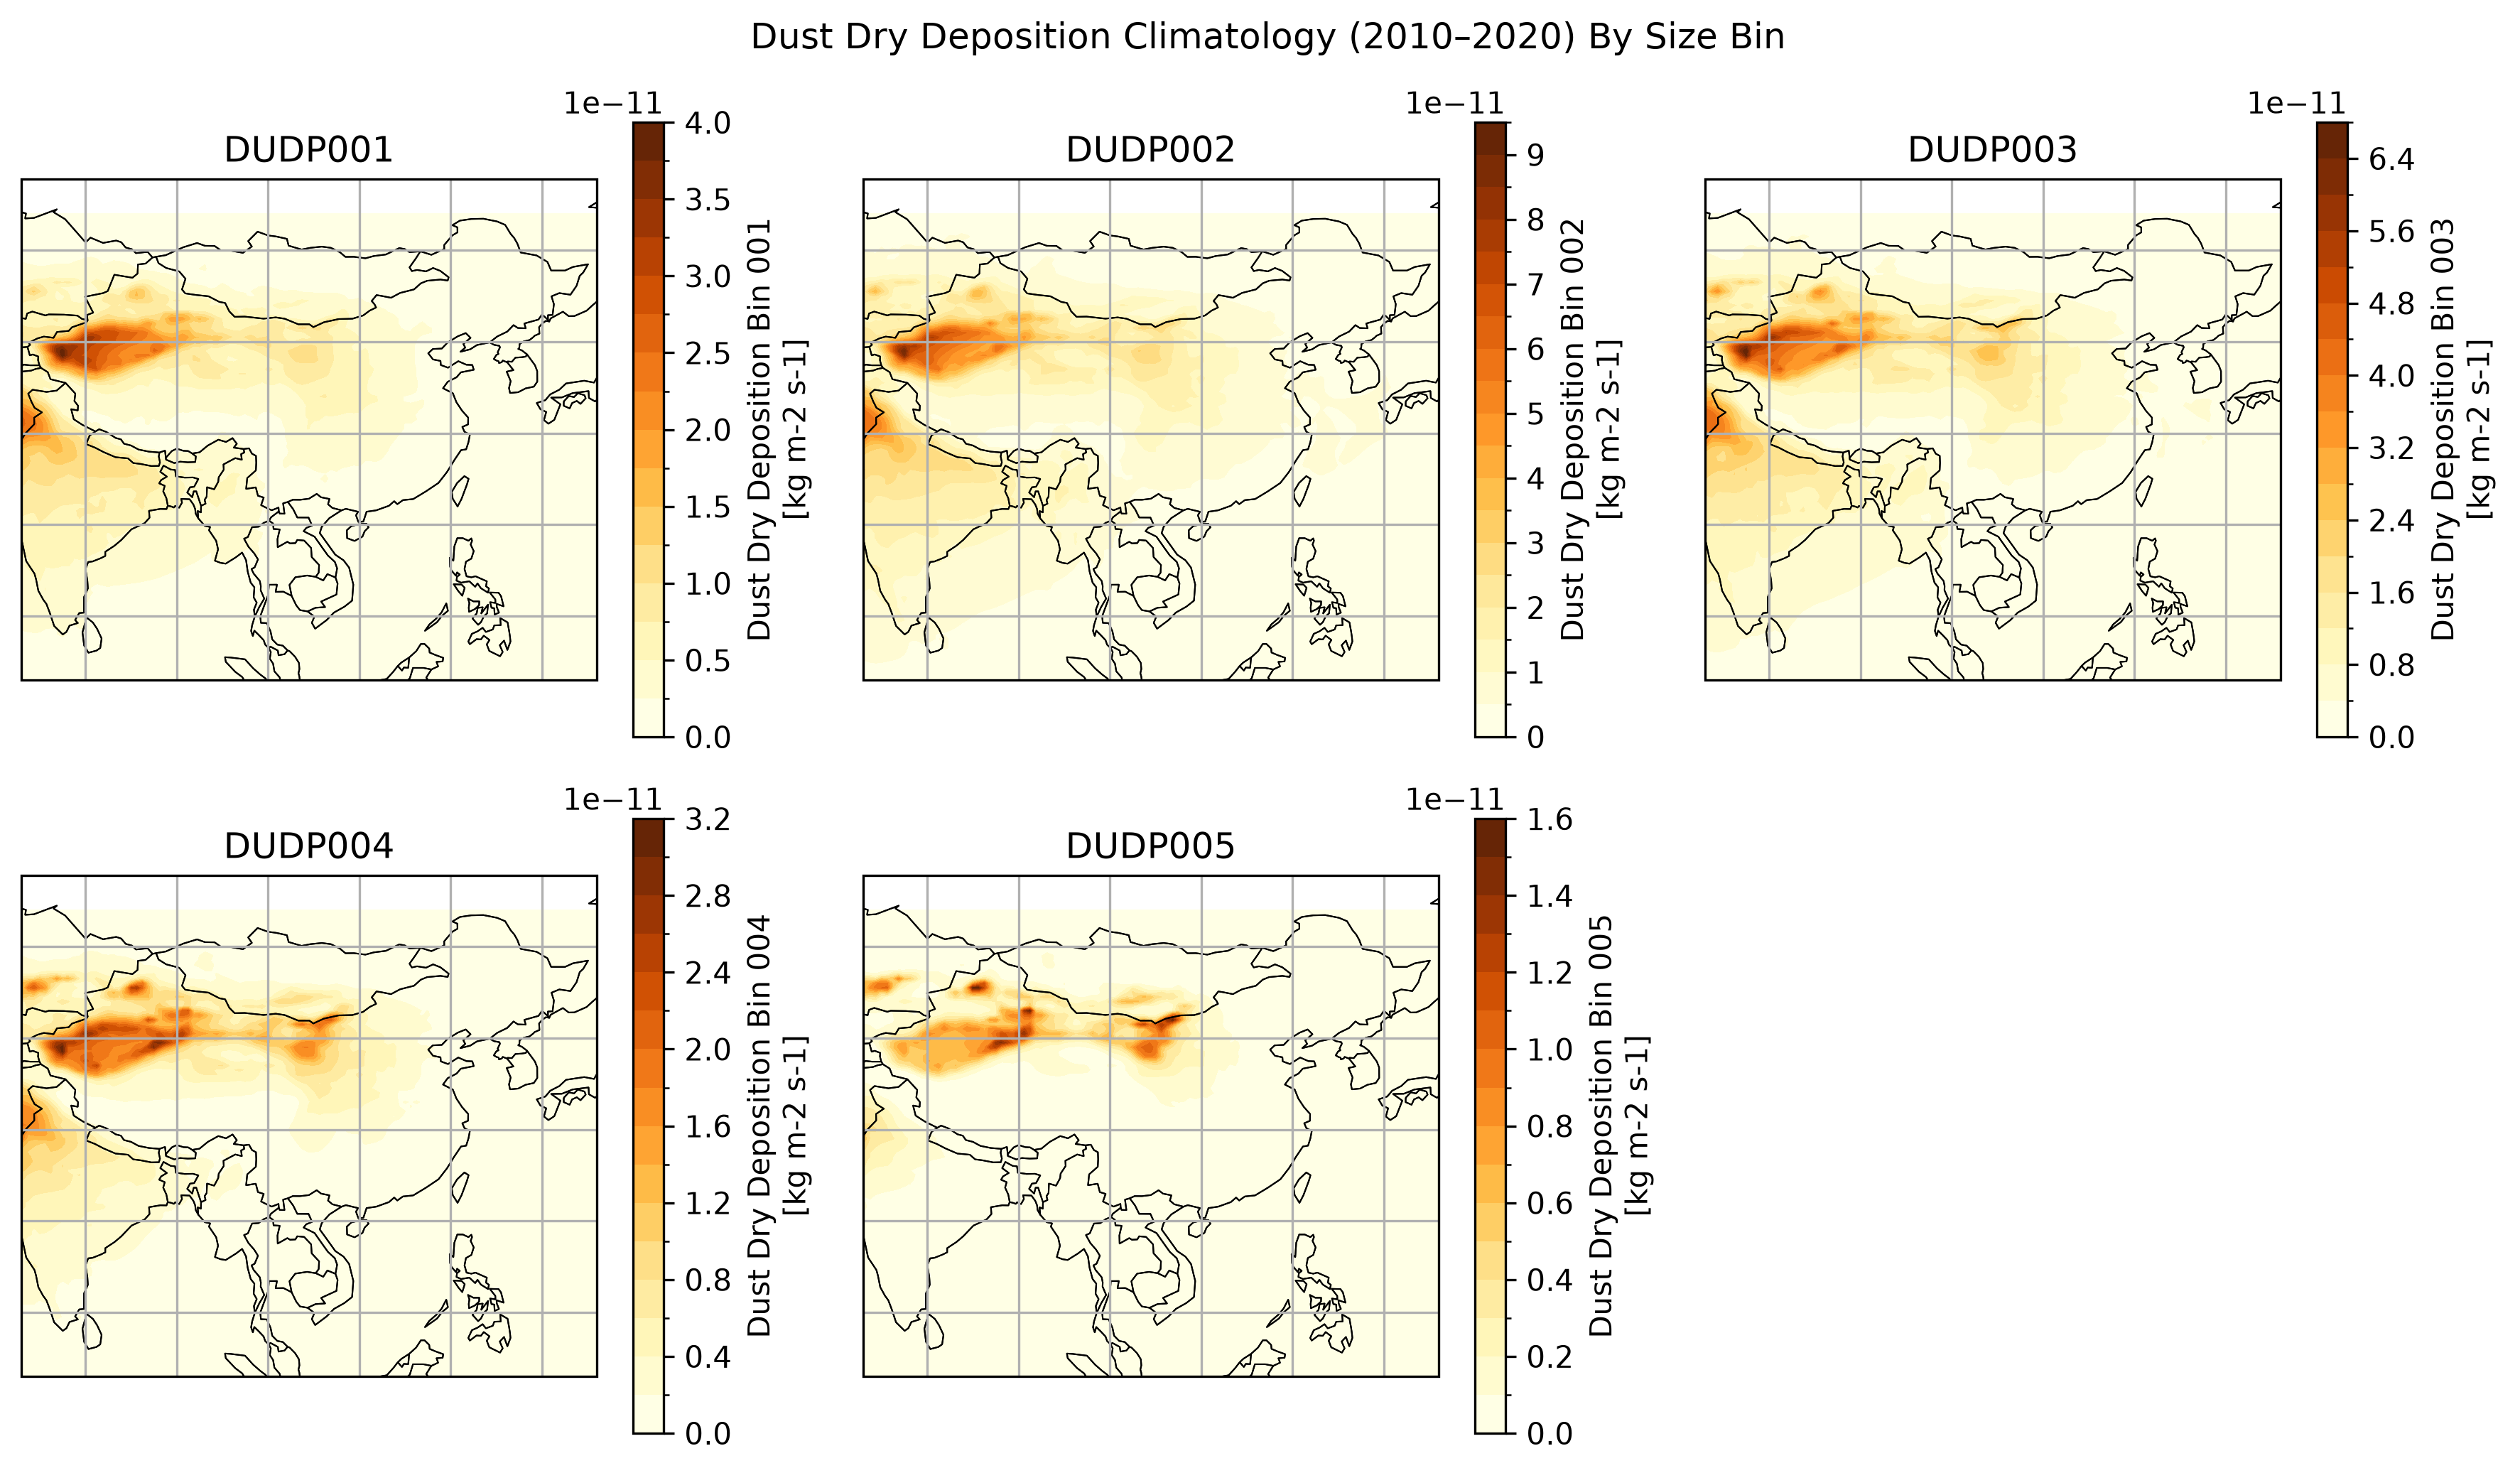

In [75]:
# 图 2：5个粒径的空间分布图
da = ds.mean(dim=['time'])

proj = ccrs.PlateCarree()
plt.figure(figsize=(12, 7), dpi=300)

for i, v in enumerate(bins):
    ax = plt.subplot(2, 3, i + 1, projection=proj)

    da[v].plot.contourf(ax=ax,transform=ccrs.PlateCarree(),levels=20,cmap='YlOrBr',add_colorbar=True)

# 国界和海岸线
    ax.add_feature(cfeature.NaturalEarthFeature
        (category='cultural',name='admin_0_countries',scale='110m',facecolor='none',edgecolor='black',linewidth=0.5,))
    ax.coastlines(linewidth=0.5)
    ax.set_extent([73, 136, 3, 54])   
    ax.gridlines()
    ax.set_title(v)

plt.suptitle('Dust Dry Deposition Climatology (2010–2020) By Size Bin')
plt.tight_layout()
plt.show()

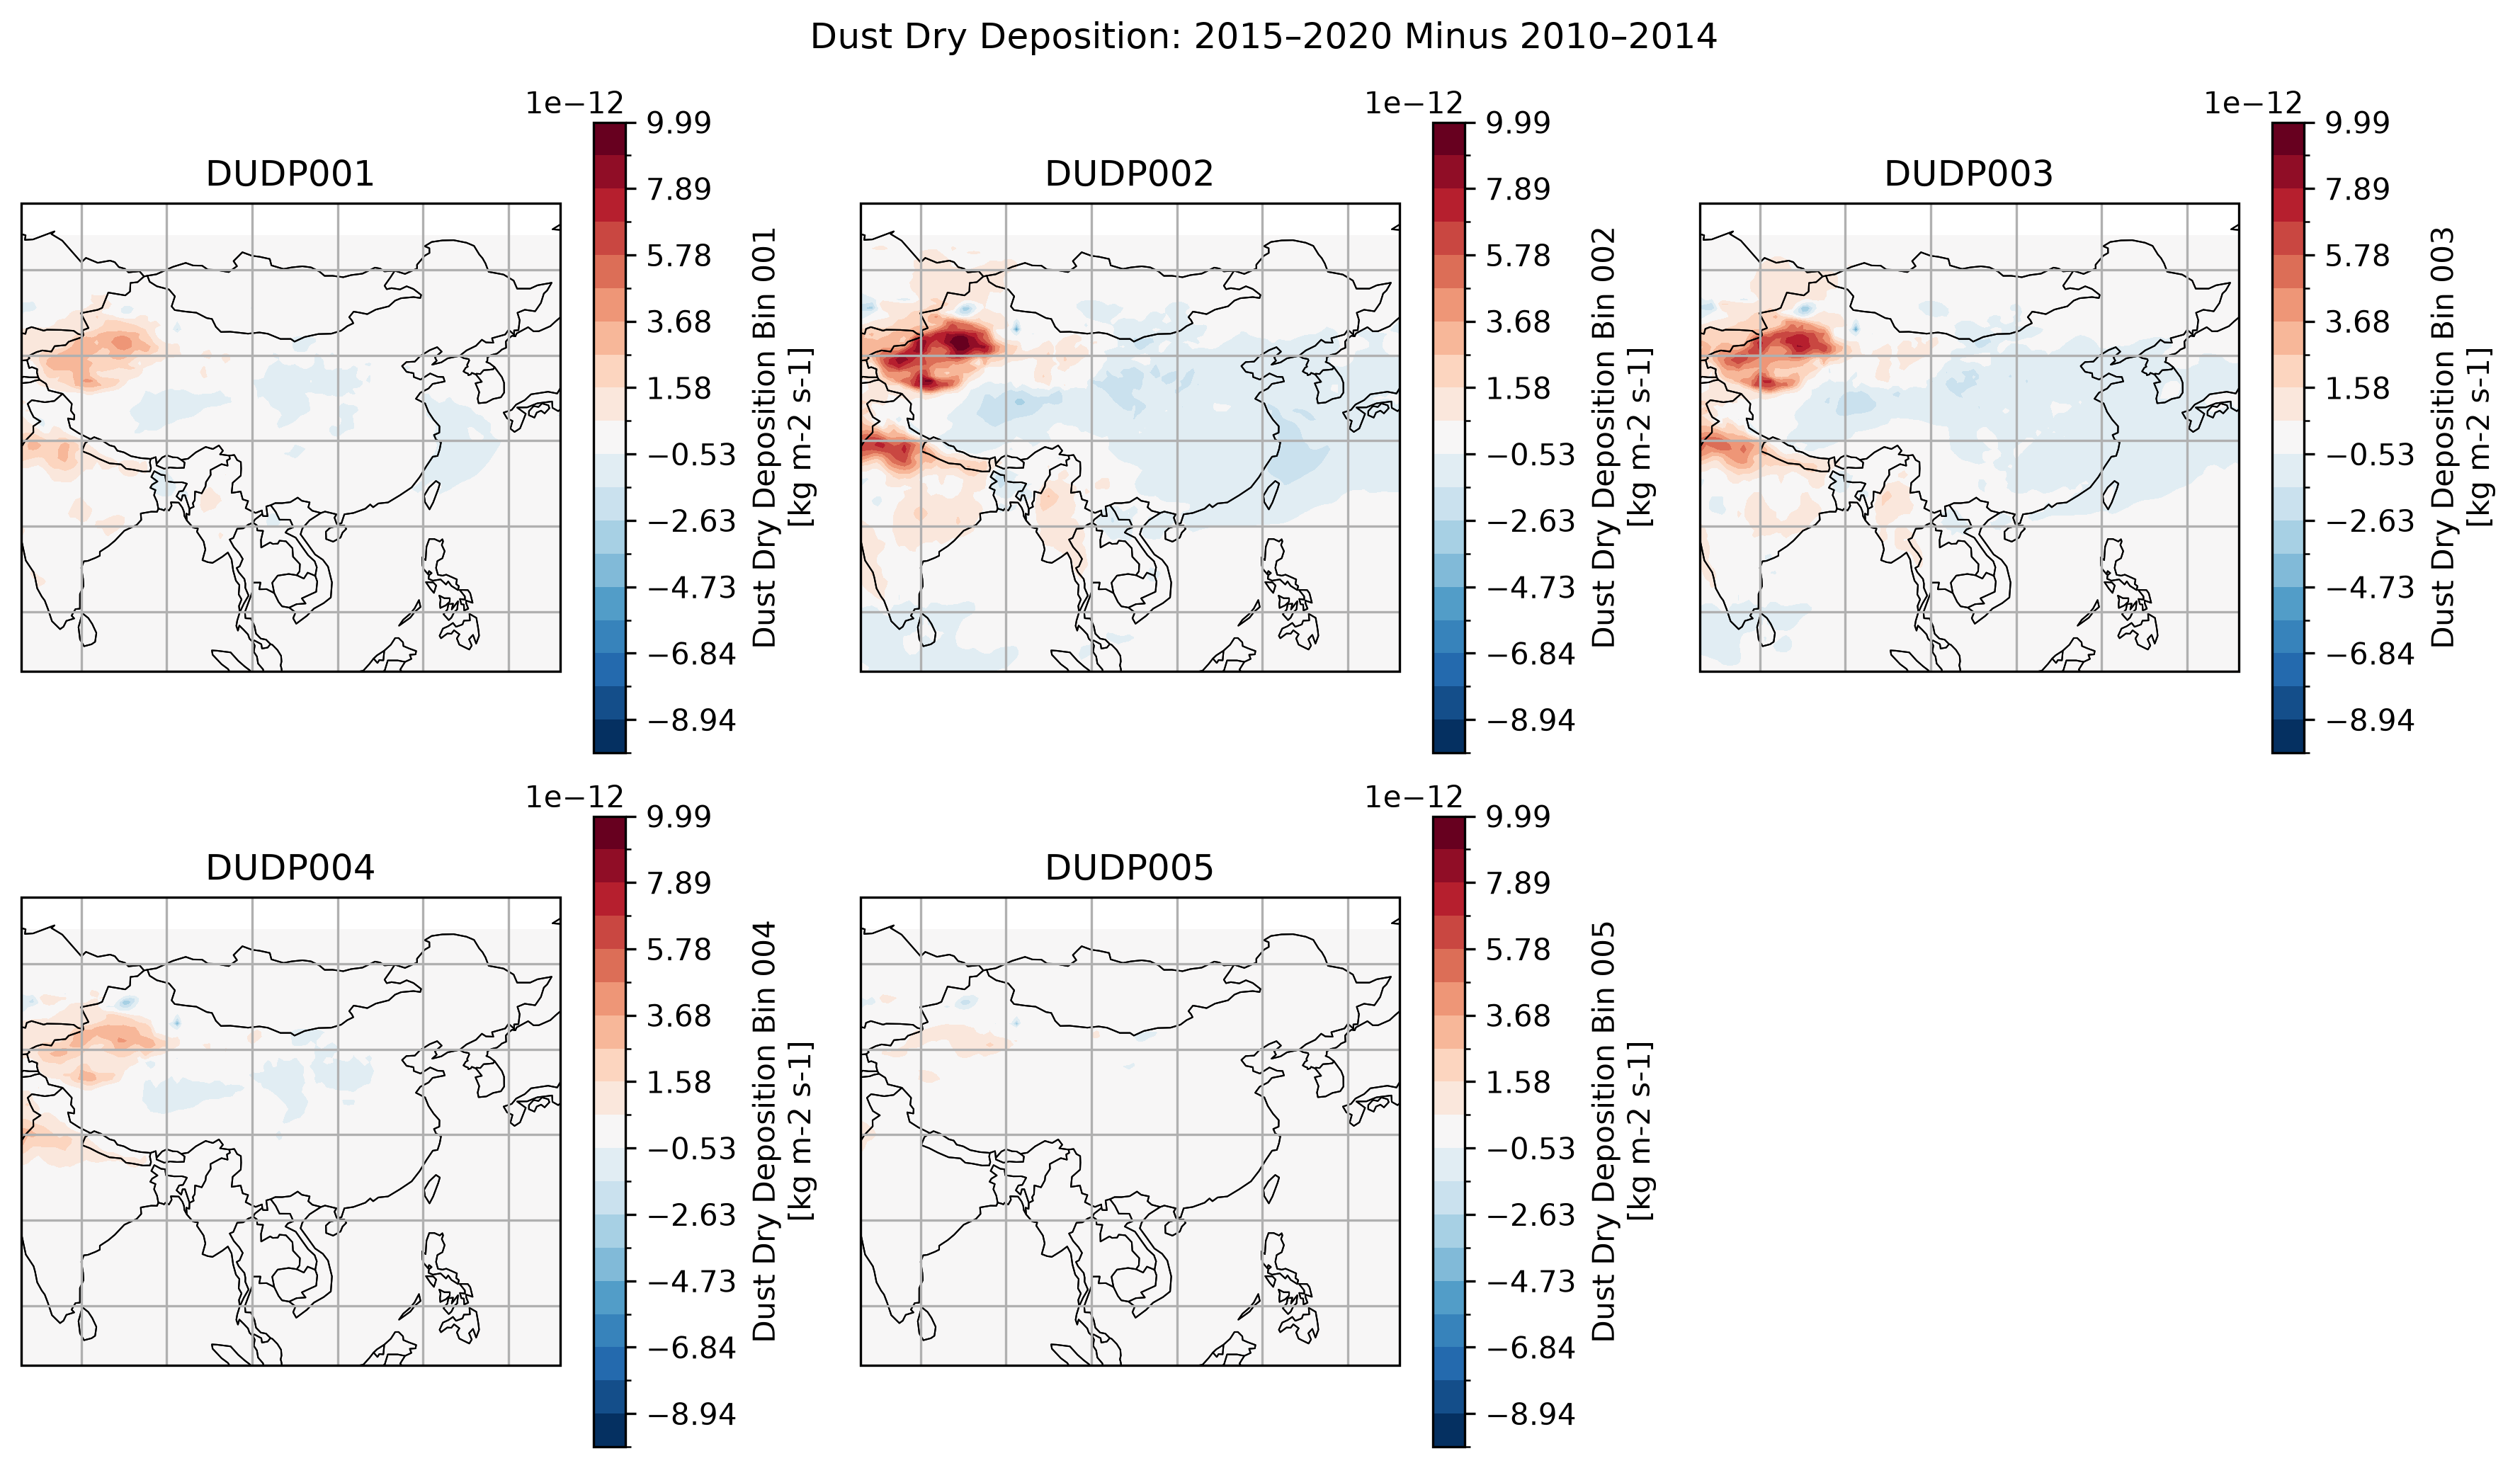

In [76]:
# 图 3：前期 VS 后期空间差异图
early = ds.sel(time=slice('2010', '2014')).mean('time')
late  = ds.sel(time=slice('2015', '2020')).mean('time')
diff  = late - early
# 统一色标范围
vmax = max(float(np.abs(diff[v]).max()) for v in bins)
if vmax == 0:
    vmax = 1e-12

proj = ccrs.PlateCarree()
plt.figure(figsize=(12, 7), dpi=300)

for i, v in enumerate(bins):
    ax = plt.subplot(2, 3, i + 1, projection=proj)

    diff[v].plot.contourf(ax=ax,transform=ccrs.PlateCarree(),levels=20,vmin=-vmax,vmax=vmax,cmap='RdBu_r',add_colorbar=True)

# 国界和海岸线
    ax.add_feature(cfeature.NaturalEarthFeature
        (category='cultural',name='admin_0_countries',scale='110m',facecolor='none',edgecolor='black',linewidth=0.5,))
    ax.coastlines(linewidth=0.5)
    ax.set_extent([73, 136, 3, 54])   
    ax.gridlines()
    ax.set_title(v)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')

plt.suptitle('Dust Dry Deposition: 2015–2020 Minus 2010–2014')
plt.tight_layout()
plt.show()

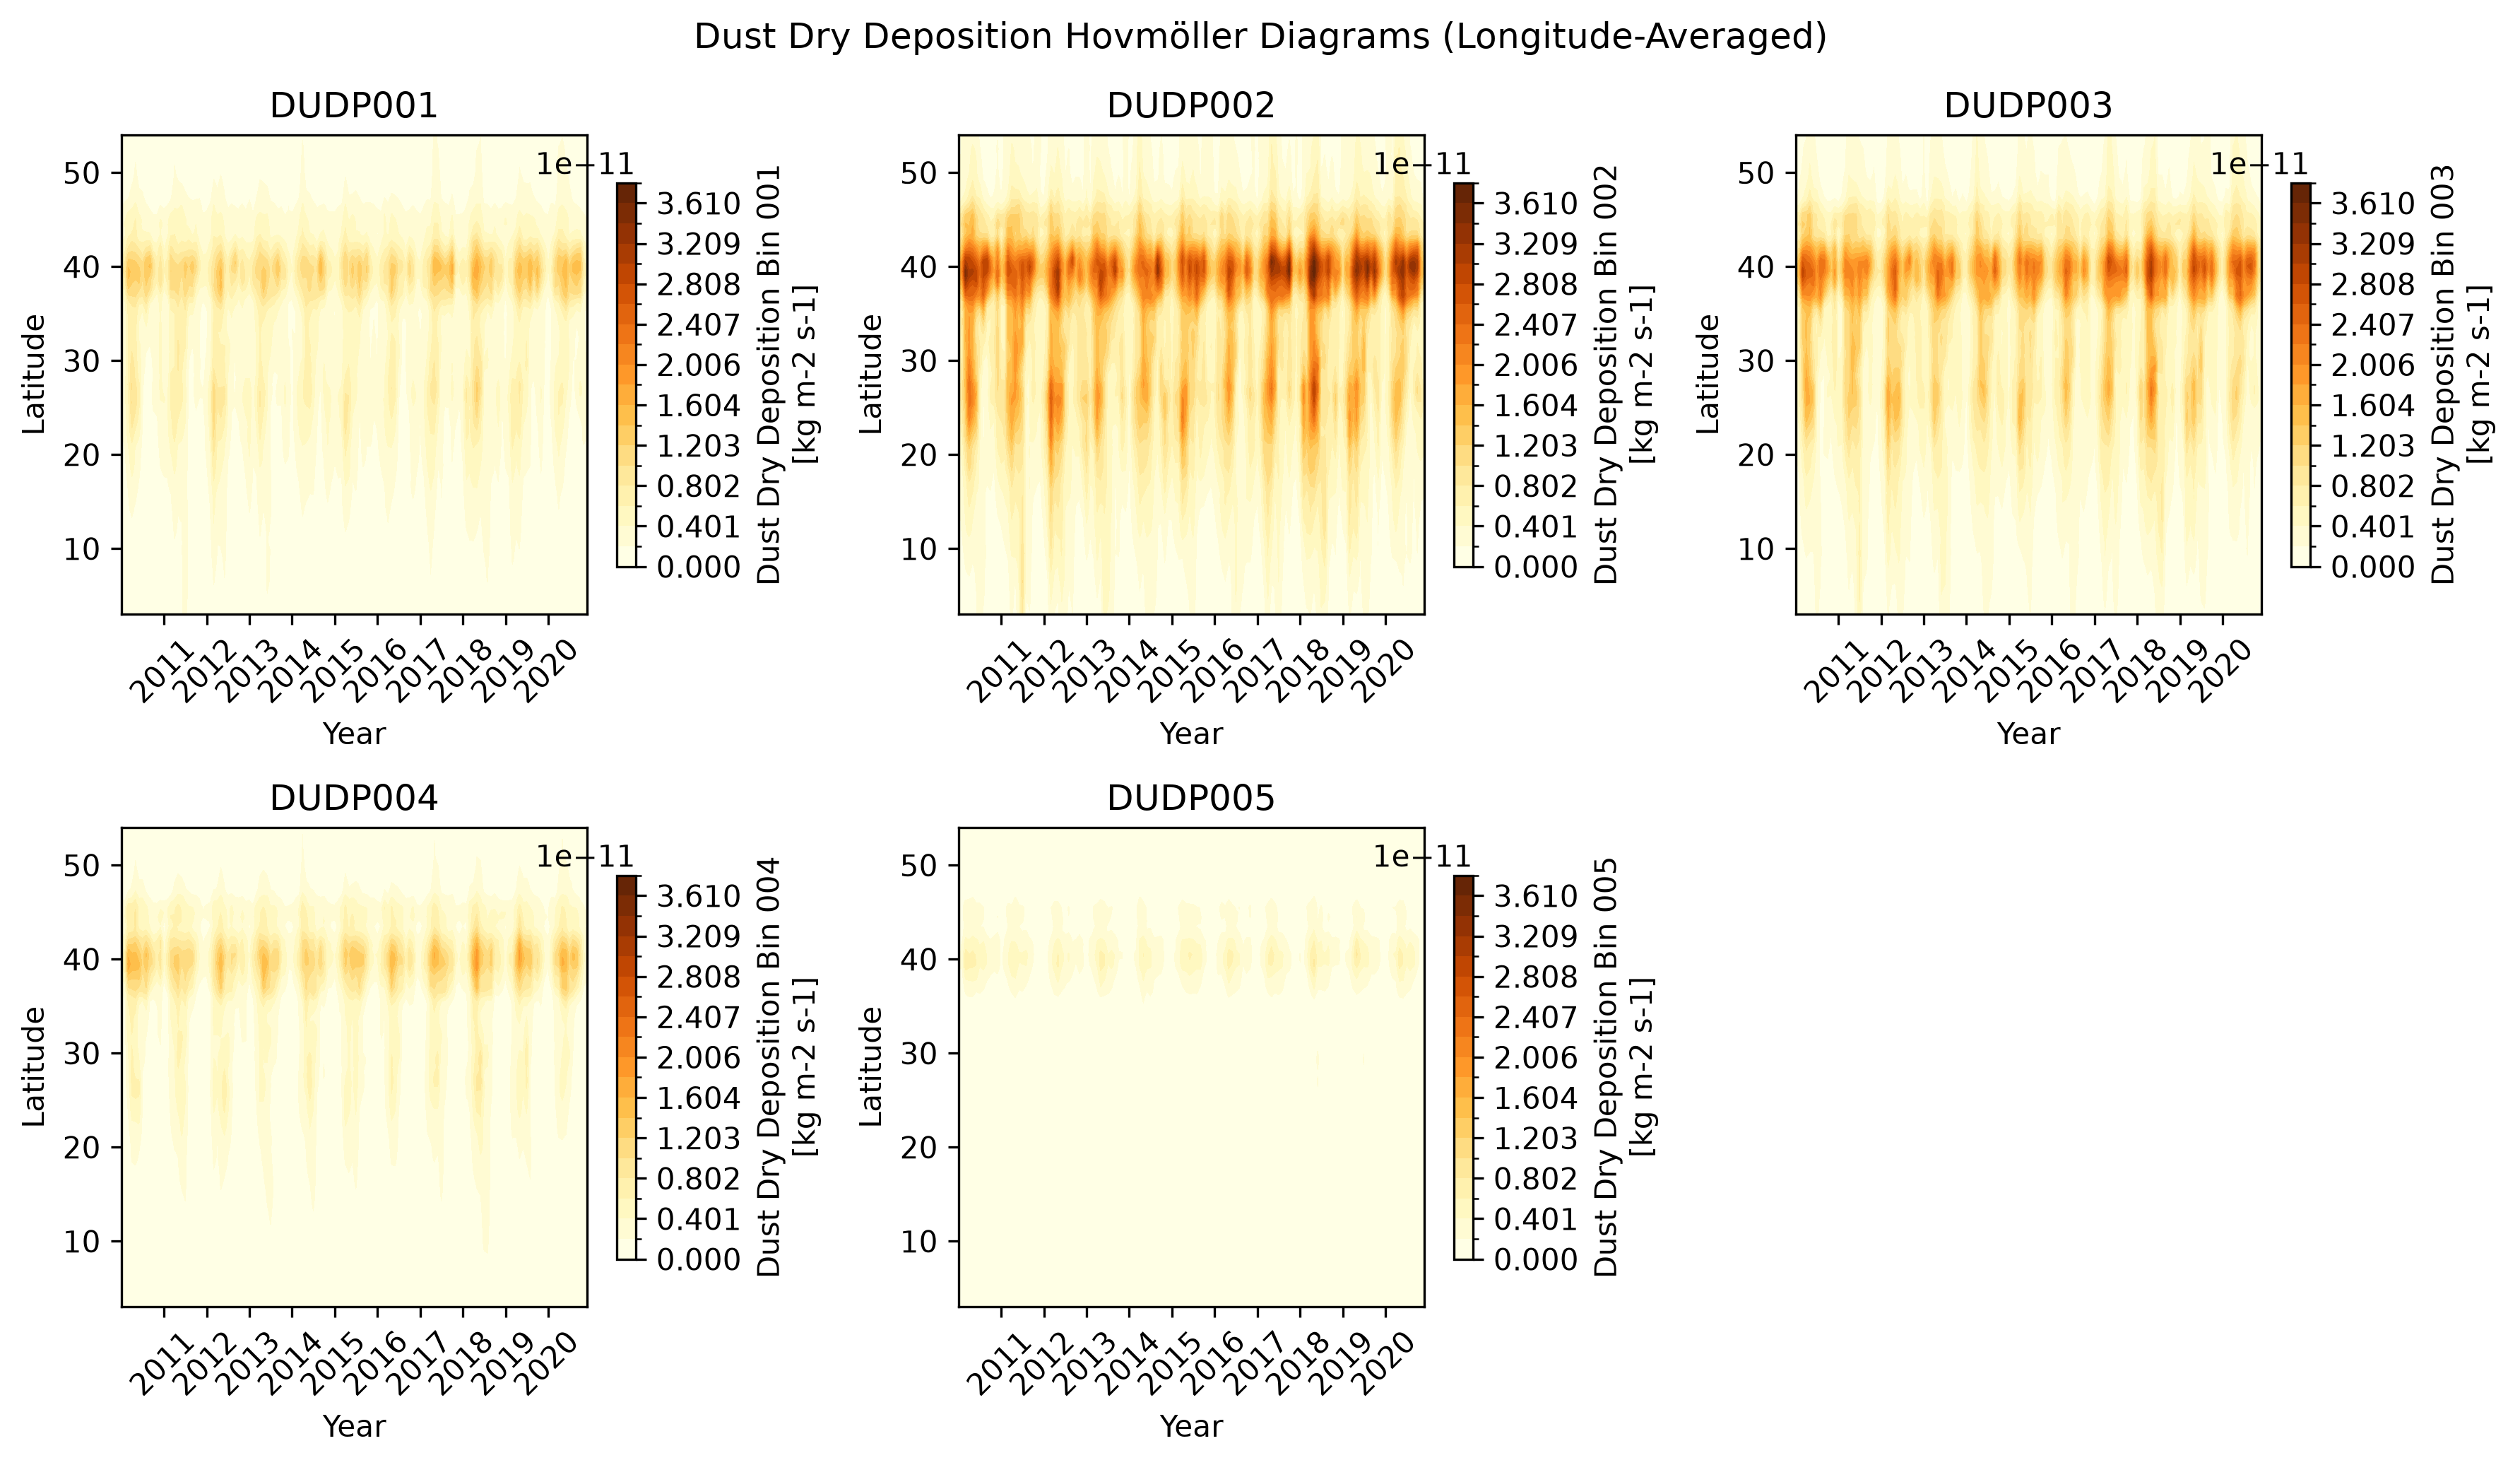

In [77]:
# 图 4：5个粒径按经度平均后的纬度-时间图
# 获取经度平均的数据
hov = {v: ds[v].mean(dim='lon') for v in bins}

# 统一色标范围
vmax = max(float(hov[v].max()) for v in bins)
if vmax == 0:
    vmax = 1e-12

plt.figure(figsize=(12, 7), dpi=300)

for i, v in enumerate(bins):
    ax = plt.subplot(2, 3, i + 1)

    hov[v].plot.contourf(ax=ax,x='time',y='lat',levels=20,cmap='YlOrBr',vmin=0,vmax=vmax,add_colorbar=True,cbar_kwargs={'shrink': 0.8},)
    
    ax.set_title(v)
    ax.set_xlabel('Year')
    ax.set_ylabel('Latitude')
    plt.xticks(rotation=45)

plt.suptitle('Dust Dry Deposition Hovmöller Diagrams (Longitude-Averaged)')
plt.tight_layout()
plt.show()

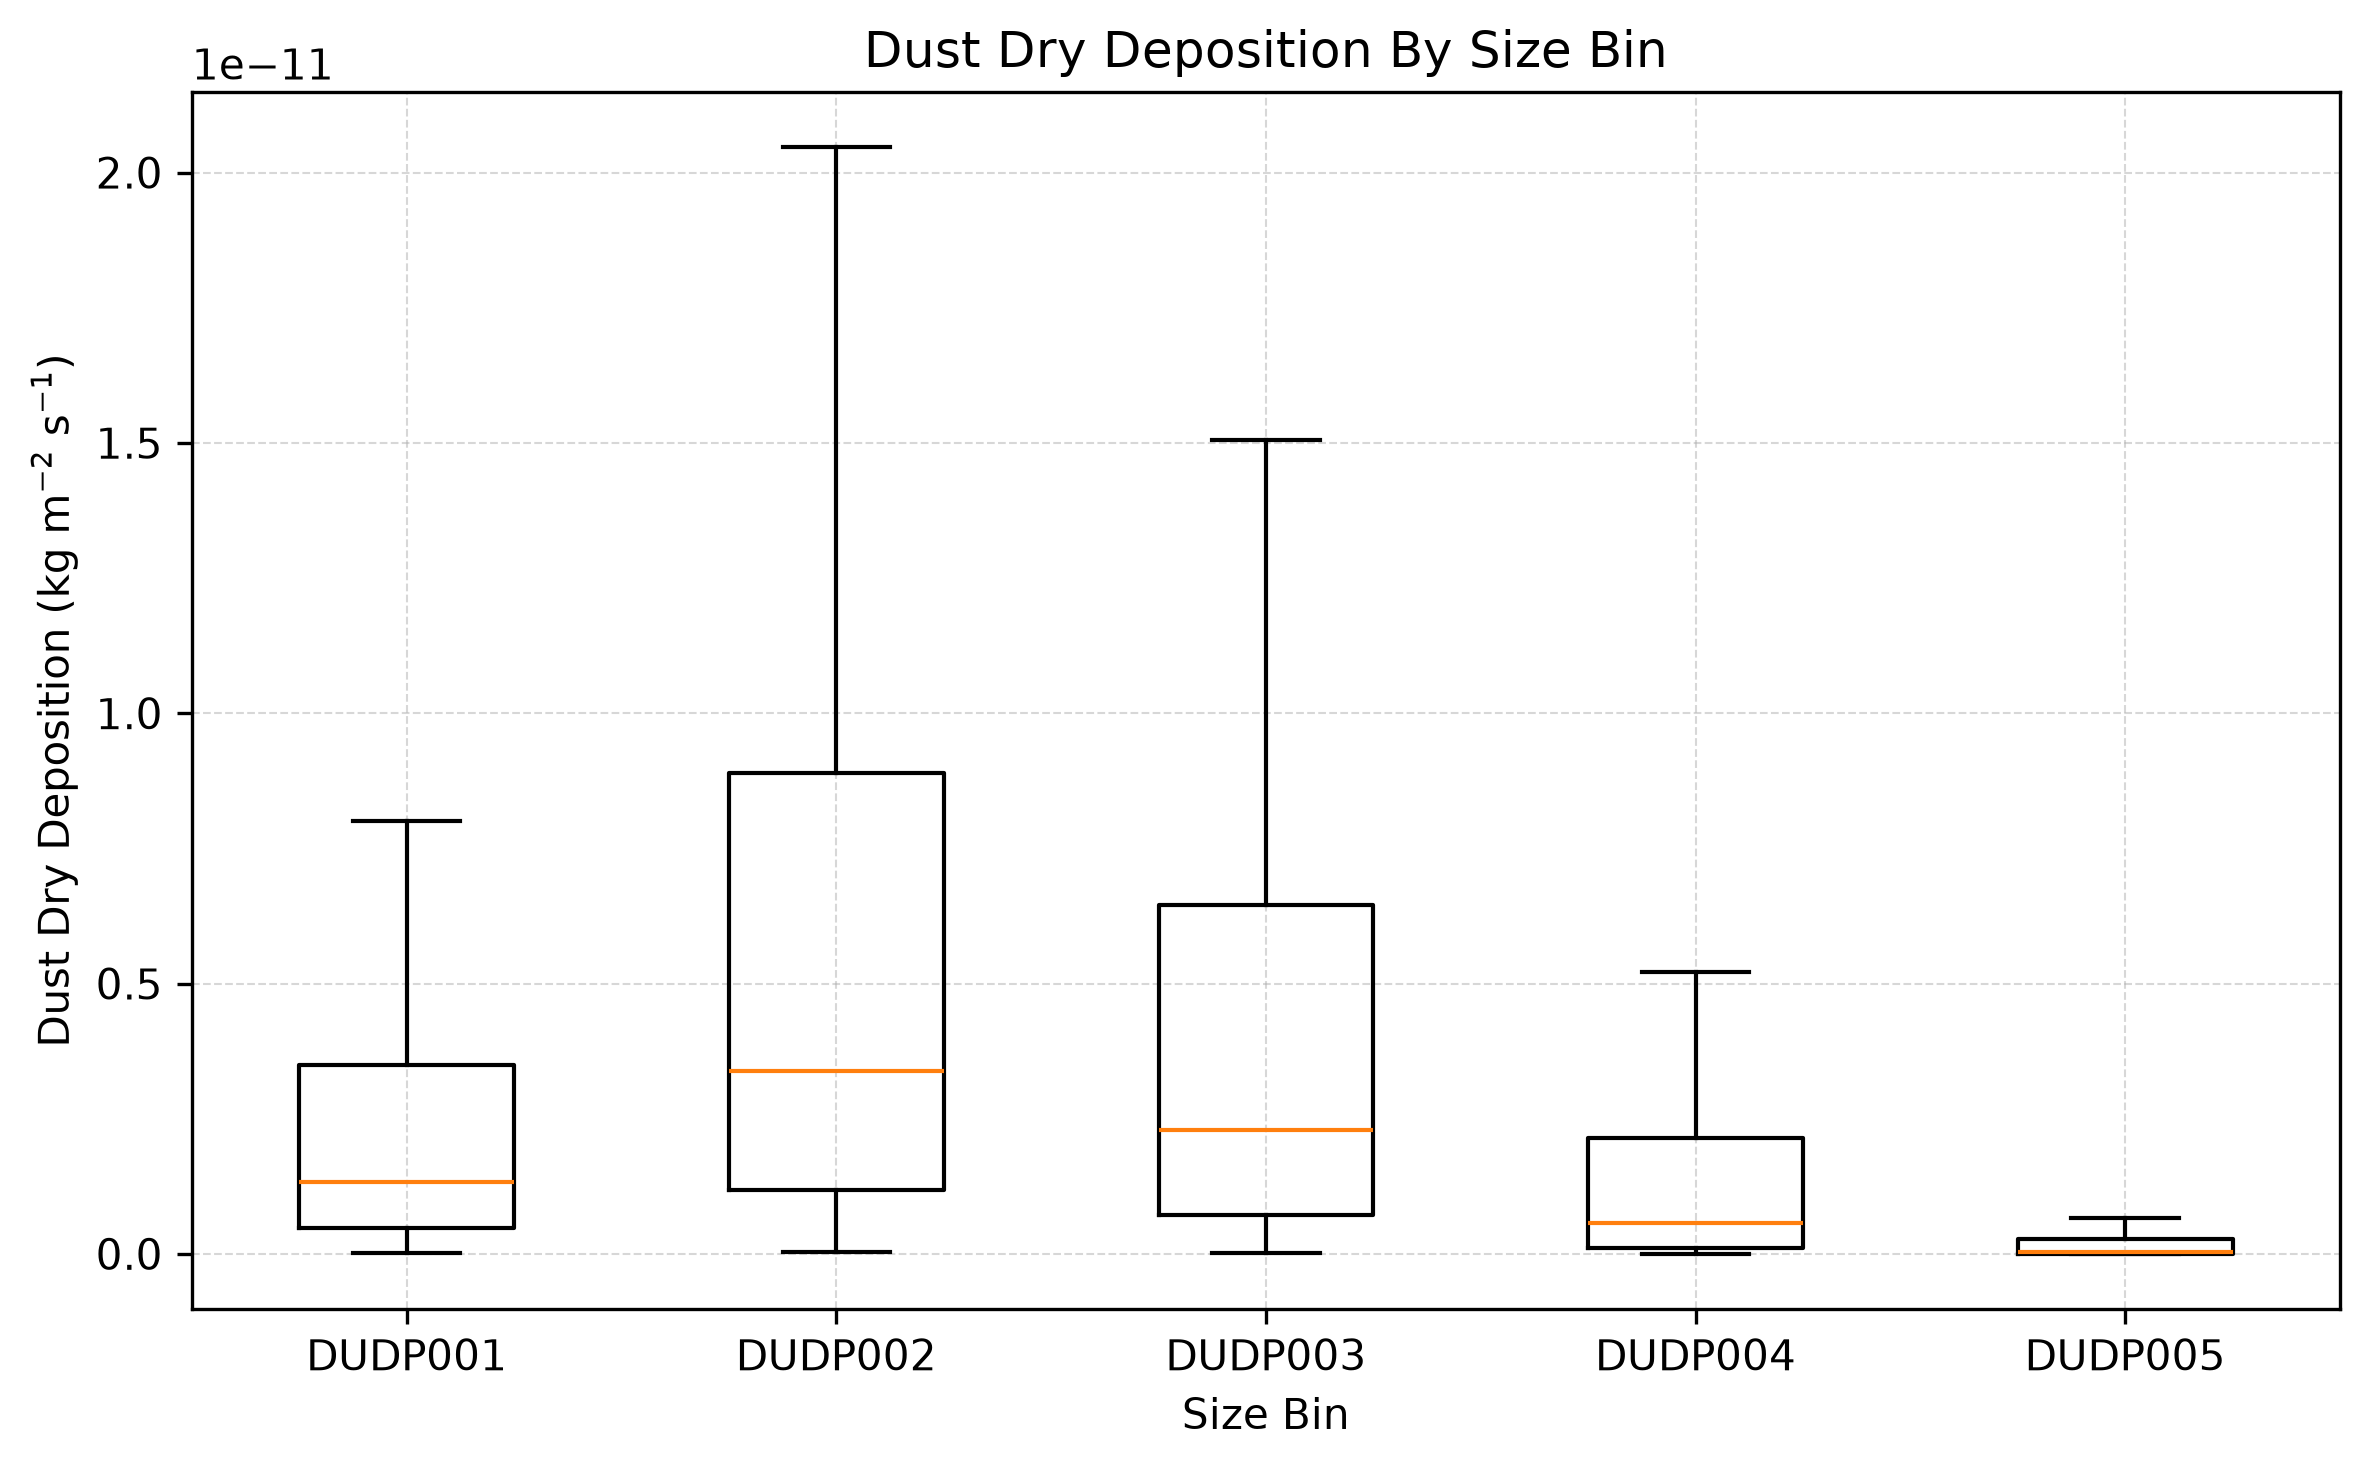

In [78]:
# 图 5：5个粒径箱线图
data = [ds[v].values.ravel() for v in bins]
plt.figure(figsize=(8, 5), dpi=300)
plt.boxplot(data, showfliers=False)
plt.xticks(range(1, len(bins) + 1), bins)

plt.xlabel("Size Bin")
plt.ylabel("Dust Dry Deposition (kg m$^{-2}$ s$^{-1}$)")
plt.title("Dust Dry Deposition By Size Bin")
plt.grid(linestyle="--", linewidth=0.5, alpha=0.5)

plt.tight_layout()
plt.show()